# 4.5 ภาระโรคที่ประมาณการ (BOD 2565) — ความจำเป็นที่ไม่ขึ้นกับการเข้าถึงบริการ

หัวข้อ 4.2.3 ระบุว่าโครงการมีเพียง "ความชุกที่วินิจฉัยแล้ว" จาก HDC ซึ่งสะท้อนการเข้าถึงการวินิจฉัยปนอยู่ด้วย
ข้อมูลภาระโรครายจังหวัด พ.ศ. 2565 ของโครงการ BOD Thailand (IHPP) ให้ตัววัดความจำเป็นอีกชนิดหนึ่ง:
DALY, YLL, YLD และอัตราตายที่ **ปรับมาตรฐานอายุ** (ASR ต่อประชากร 100,000 คน, ประชากรมาตรฐาน WHO) 174 กลุ่มโรค 77 จังหวัด
และไฟล์คู่กันที่แยก **8 กลุ่มอายุ** (จำนวน อัตรา และประชากรกลางปี) ซึ่งทำให้คำนวณภาระรวมจริงและฉายตามการสูงวัยได้

| ส่วน | คำถาม | ใช้ใน |
|---|---|---|
| A | ภาระโรคต่างกันระหว่างจังหวัดเพียงใด และมาจากอะไร | 4.2.3 |
| B | ความชุกที่บันทึกใน HDC สอดคล้องกับภาระโรคที่ประมาณการหรือไม่ และความต่างสัมพันธ์กับจำนวนแพทย์หรือไม่ | 4.2.3 |
| C | ภาระโรคช่วยทำนายบริการเพิ่มจากอายุและความชุกที่บันทึกหรือไม่ (fold เดียวกับ M0–M5) | 4.2.3 |
| D | กำลังคนกระจายตามภาระโรคหรือไม่ (inverse care law) และจังหวัดที่ควรให้ความสำคัญเปลี่ยนหรือไม่ | 4.3 |
| E | ดัชนีภาระโรคที่ส่งต่อให้บทที่ 5 | 5 |

**ข้อจำกัดที่ต้องถือตลอด** (1) เป็นค่าประมาณจากแบบจำลอง ไม่ใช่จำนวนที่นับได้ และอาจใช้ข้อมูลบริการบางส่วนเป็นข้อมูลนำเข้า จึงไม่ใช่ "ค่าจริง" ที่เป็นอิสระโดยสมบูรณ์
(2) มีเพียงปีเดียว (2565) จึงใช้เป็นคุณลักษณะคงที่ของจังหวัด หรือใช้อัตรารายอายุปี 2565 คงที่กับประชากรปีอื่น (3) ASR ตัดผลของโครงสร้างอายุออก — ภาระรวมจริงของจังหวัดที่แก่กว่าจะสูงกว่า ASR ส่วนภาระคาดหมายจากอัตรารายอายุรวมผลนี้ไว้
(4) ปี 2565 เป็นปีที่ได้รับผลจากโควิด-19 ดัชนีเพื่อการวางแผนจึงตัดสาเหตุ B5 (โควิด-19) ออก และเก็บดัชนีทุกสาเหตุไว้เป็นความไว

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "analysis.toml").exists())
sys.path.insert(0, str(_root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import statsmodels.api as sm
from scipy.stats import spearmanr
from IPython.display import display

from chapter4 import config as C, panels as P, metrics as M, models as MD, reporting as R
from chapter4.ingest import load

pd.options.display.max_columns = 40
pd.options.display.width = 200
FONT = R.setup_style()
S = R.Section("4_5")
Y0, Y1 = C.Y0, C.Y1
CAD = C.CADRES
EN = C.CADRE_EN
BC = C.CFG["burden"]
BY = BC["year"]
BK = int(P.key().query("is_bangkok").prov_code.iloc[0])
KEY = P.key()[lambda d: ~d.is_bangkok].set_index("prov_code")
NAME = KEY.province.to_dict()
print(C.effective_config("4_5"))

# dependency on 4.2: the fold assignment (to confirm identical folds) and the age-weighted population
T42 = C.OUTPUTS / "chapter4_2" / "tables"
need = ["T423_FOLD_ASSIGNMENT.csv", "T423_AGE_WEIGHTED_POPULATION.csv", "T423_MODEL_VALIDATION.csv"]
missing = [f for f in need if not (T42 / f).exists()]
if missing:
    raise FileNotFoundError(f"missing 4.2 outputs {missing} - run: python -m chapter4.build --section 4.2")
AWP = pd.read_csv(T42 / "T423_AGE_WEIGHTED_POPULATION.csv", encoding="utf-8-sig")
T43 = C.OUTPUTS / "chapter4_3" / "tables"
PRI43 = pd.read_csv(T43 / "T43_PRIORITY_RANKS.csv", encoding="utf-8-sig") if (T43 / "T43_PRIORITY_RANKS.csv").exists() else None

{
 "years": {
  "long_first": 2013,
  "long_last": 2025,
  "casemix_first": 2018,
  "casemix_last": 2025,
  "morbidity_first": 2022,
  "morbidity_last": 2025,
  "flow_first_fy": 2017,
  "flow_last_complete_fy": 2025,
  "recent_window_years": 5,
  "pre_transfer_last": 2022,
  "covid_years": [
   2020,
   2021,
   2022
  ]
 },
 "geography": {
  "bangkok": "กรุงเทพมหานคร",
  "provincial_exclude": [
   "กรุงเทพมหานคร"
  ]
 },
 "burden": {
  "year": 2022,
  "exclude_causes": [
   "B5"
  ],
  "groups": {
   "CMNN": "ABCDEFG",
   "NCD": "HIJKLMNOPQRS",
   "INJ": "TUV"
  },
  "hdc_match": {
   "prev_dm": "O1",
   "prev_ht": "I4",
   "prev_ckd_3_5": "O2",
   "prev_copd": "J1",
   "prev_stroke": "I3",
   "prev_chd": "I2"
  },
  "cadre_causes": {
   "ทันตแพทย์": [
    "S6"
   ]
  },
  "age_groups": [
   [
    0,
    4
   ],
   [
    5,
    14
   ],
   [
    15,
    29
   ],
   [
    30,
    44
   ],
   [
    45,
    59
   ],
   [
    60,
    69
   ],
   [
    70,
    79
   ],
   [
    80,
    200

---
# ส่วน A — ภาระโรคต่างกันระหว่างจังหวัดเพียงใด
## A1. สัญญาข้อมูลและการตรวจสอบ
ตรวจซ้ำเงื่อนไขของแหล่งข้อมูล: 77 จังหวัด × 174 กลุ่มโรค, DALY = YLL + YLD, ไม่มีค่าว่างหรือคีย์ซ้ำ, รหัส P<nn> ตรงกับชื่อจังหวัด (ตรวจตอนนำเข้า)

In [2]:
bod = load("bod_province")
BW = P.burden_wide().set_index("prov_code")
bw76 = BW.drop(index=BK)
covid = bod[bod.cause_code.isin(BC["exclude_causes"])].groupby("prov_code").asr_daly.sum()
checks = pd.DataFrame([
    dict(check="provinces", value=bod.prov_code.nunique(), expected="77"),
    dict(check="causes per province (min)", value=bod.groupby("prov_code").cause_code.nunique().min(), expected="174"),
    dict(check="max |DALY - YLL - YLD|", value=float((bod.asr_daly - bod.asr_yll - bod.asr_yld).abs().max()), expected="< 1e-6"),
    dict(check="duplicate province-cause keys", value=int(bod.duplicated(["prov_code", "cause_code"]).sum()), expected="0"),
    dict(check="non-finite or negative values", value=int((~np.isfinite(bod[["asr_daly", "asr_yll", "asr_yld", "asr_death"]])).sum().sum()
                                                        + (bod[["asr_daly", "asr_yll", "asr_yld", "asr_death"]] < 0).sum().sum()), expected="0"),
    dict(check="zero-valued province-cause DALY cells", value=int((bod.asr_daly == 0).sum()), expected="kept (observed zeros)"),
    dict(check="excluded causes (planning index)", value=len(BC["exclude_causes"]), expected=", ".join(BC["exclude_causes"])),
])
ba = load("bod_province_age")
who = np.array(BC["who_standard"], float)
edges = [0, 1, 3, 6, 9, 12, 14, 16, len(who)]
w8 = np.array([who[a:b].sum() for a, b in zip(edges[:-1], edges[1:])]); w8 /= w8.sum()
rt8 = (ba.assign(rate=1e5 * ba.daly / ba.mid_pop).pivot_table(index=["prov_code", "cause_code"], columns="age_group", values="rate")
       .sort_index(axis=1))
asr_re = pd.Series(rt8.to_numpy() @ w8, index=rt8.index)
asr_pub = bod.set_index(["prov_code", "cause_code"]).asr_daly.reindex(asr_re.index)
rel_gap = float(((asr_re - asr_pub).abs() / asr_pub.clip(lower=1.0)).max())
midpop = ba.drop_duplicates(["prov_code", "age_group"]).groupby("prov_code").mid_pop.sum()
reg22 = P.registers().query("register == 'civil_age' and year == @BY").set_index("prov_code").population
checks = pd.concat([checks, pd.DataFrame([
    dict(check="age file: province x cause x age rows", value=len(ba), expected=f"{77 * 174 * 8}"),
    dict(check="age file: max relative gap, re-standardized vs published ASR (WHO weights, 8 groups)", value=rel_gap, expected="< 1e-3 (weights published to 0.01)"),
    dict(check="age file: mid-year population / civil register 2022, min", value=float((midpop / reg22).min()), expected="close to 1"),
    dict(check="age file: mid-year population / civil register 2022, max", value=float((midpop / reg22).max()), expected="close to 1"),
])], ignore_index=True)
S.claim("c45_asr_repro_gap_pct", 100 * rel_gap, "{:.3f}", "%")
S.claim("c45_midpop_ratio_max_pct", 100 * float((midpop / reg22 - 1).abs().max()), "{:.1f}", "%")
S.table("T45_BOD_SOURCE_CHECKS", checks, "การตรวจสอบข้อมูลภาระโรครายจังหวัด พ.ศ. 2565 (BOD Thailand)")
display(checks)
S.claim("c45_n_causes", bod.cause_code.nunique(), "int", "กลุ่มโรค")
S.claim("c45_covid_share_median", 100 * (covid.drop(index=BK) / bw76.bod_daly_allcause).median(), "{:.1f}", "%",
        note="share of all-cause ASR DALY from COVID-19 (B5), 2022, median of 76 provinces")
S.claim("c45_covid_share_max", 100 * (covid.drop(index=BK) / bw76.bod_daly_allcause).max(), "{:.1f}", "%")

,check,value,expected
0,provinces,7.700000e+01,77
1,causes per province (min),1.740000e+02,174
2,max |DALY - YLL - YLD|,2.849835e-10,< 1e-6
3,duplicate province-cause keys,0.000000e+00,0
4,non-finite or negative values,0.000000e+00,0
5,zero-valued province-cause DALY cells,1.712000e+03,kept (observed zeros)
6,excluded causes (planning index),1.000000e+00,B5
7,age file: province x cause x age rows,1.071840e+05,107184
8,"age file: max relative gap, re-standardized vs...",2.975642e-04,< 1e-3 (weights published to 0.01)
9,age file: mid-year population / civil register...,9.999131e-01,close to 1


5.754095174402226

## A2. ภาระโรคเชิงโครงสร้างรายจังหวัด (ไม่รวมโควิด-19)
ผลรวม ASR ของทุกกลุ่มโรคในจังหวัดเดียวกันทำได้ (ประชากรมาตรฐานเดียวกัน) แต่ **ไม่รวมหรือเฉลี่ย ASR ข้ามจังหวัด** เป็นค่าระดับประเทศ
จึงรายงานมัธยฐาน ช่วง และ P90/P10 ของ 76 จังหวัดแทน

In [3]:
PROV = bw76.copy()
PROV["province"] = PROV.index.map(NAME)
PROV["health_region"] = KEY.health_region.reindex(PROV.index)
for g in ["cmnn", "ncd", "inj"]:
    PROV[f"share_{g}"] = PROV[f"bod_daly_{g}"] / PROV.bod_daly
PROV["rank_daly_high_to_low"] = PROV.bod_daly.rank(ascending=False, method="first").astype(int)
cols = ["province", "health_region", "bod_daly", "bod_yll", "bod_yld", "bod_death", "bod_daly_cmnn", "bod_daly_ncd", "bod_daly_inj",
        "share_cmnn", "share_ncd", "share_inj", "bod_yll_share", "bod_daly_allcause", "rank_daly_high_to_low"]
TPROV = PROV[cols].reset_index().sort_values("rank_daly_high_to_low")
S.table("T45_BOD_PROVINCE", TPROV, "ภาระโรคปรับมาตรฐานอายุรายจังหวัด พ.ศ. 2565 (ต่อประชากร 100,000 คน; ไม่รวมโควิด-19 ยกเว้นคอลัมน์ทุกสาเหตุ)", main=True)
q = PROV.bod_daly
S.claim("c45_daly_median", q.median(), "int", "DALY ต่อ 100,000")
S.claim("c45_daly_min", q.min(), "int", "DALY ต่อ 100,000")
S.claim("c45_daly_max", q.max(), "int", "DALY ต่อ 100,000")
S.text_claim("c45_daly_min_prov", NAME[q.idxmin()])
S.text_claim("c45_daly_max_prov", NAME[q.idxmax()])
S.claim("c45_daly_p90p10", q.quantile(.9) / q.quantile(.1), "{:.2f}", "เท่า")
S.claim("c45_daly_max_min", q.max() / q.min(), "{:.2f}", "เท่า")
S.claim("c45_daly_cv", 100 * q.std() / q.mean(), "{:.1f}", "%")
S.claim("c45_yll_share_median", 100 * PROV.bod_yll_share.median(), "{:.1f}", "%")
S.claim("c45_ncd_share_median", 100 * PROV.share_ncd.median(), "{:.1f}", "%")
S.claim("c45_inj_share_median", 100 * PROV.share_inj.median(), "{:.1f}", "%")
S.claim("c45_cmnn_share_median", 100 * PROV.share_cmnn.median(), "{:.1f}", "%")
S.claim("c45_bkk_daly", BW.loc[BK, "bod_daly"], "int", "DALY ต่อ 100,000", note="Bangkok, reported only; excluded from provincial analyses")
top5 = PROV.sort_values("bod_daly", ascending=False).province.head(5).tolist()
low5 = PROV.sort_values("bod_daly").province.head(5).tolist()
S.text_claim("c45_daly_top5", ", ".join(top5))
S.text_claim("c45_daly_low5", ", ".join(low5))
# variation by component: which part of the burden varies most between provinces
var = pd.DataFrame([dict(component=c, median=PROV[c].median(), p10=PROV[c].quantile(.1), p90=PROV[c].quantile(.9),
                         p90_p10=PROV[c].quantile(.9) / PROV[c].quantile(.1),
                         sd_share_of_total_sd=PROV[c].std() / PROV.bod_daly.std())
                    for c in ["bod_daly", "bod_yll", "bod_yld", "bod_daly_cmnn", "bod_daly_ncd", "bod_daly_inj"]])
S.table("T45_BOD_COMPONENT_VARIATION", var, "การกระจายระหว่างจังหวัดขององค์ประกอบภาระโรค (76 จังหวัด)")
display(var.round(3))
for r in var.itertuples():
    S.claim(f"c45_p90p10_{r.component}", r.p90_p10, "{:.2f}", "เท่า")
# Between-province variance of all-cause DALY: share contributed by each group (covariance decomposition, exact)
cv_ = {g: np.cov(PROV[f"bod_daly_{g}"], PROV.bod_daly)[0, 1] / PROV.bod_daly.var() for g in ["cmnn", "ncd", "inj"]}
for g, v in cv_.items():
    S.claim(f"c45_var_share_{g}", 100 * v, "{:.1f}", "%", note="cov(group, total)/var(total), shares add to 100")
print({g: round(100 * v, 1) for g, v in cv_.items()})

,component,median,p10,p90,p90_p10,sd_share_of_total_sd
0,bod_daly,25139.671,20907.581,27334.025,1.307,1.000
1,bod_yll,19453.458,15847.619,21624.124,1.365,0.849
2,bod_yld,5511.412,4764.161,6429.040,1.349,0.261
3,bod_daly_cmnn,2768.328,2268.111,3283.894,1.448,0.160
4,bod_daly_ncd,17583.640,14485.743,19084.200,1.317,0.715
5,bod_daly_inj,4621.800,3533.341,5664.626,1.603,0.345


{'cmnn': np.float64(8.4), 'ncd': np.float64(67.5), 'inj': np.float64(24.1)}


## A3. สาเหตุที่มีภาระมากที่สุด และสาเหตุที่ต่างระหว่างจังหวัดมากที่สุด

In [4]:
b76 = bod[bod.prov_code != BK]
top = (b76.groupby(["cause_code", "cause_en", "cause_th", "cause_group"]).asr_daly
          .agg(median="median", p10=lambda s: s.quantile(.1), p90=lambda s: s.quantile(.9), min="min", max="max").reset_index())
top["p90_p10"] = top.p90 / top.p10.replace(0, np.nan)
yldm = b76.groupby("cause_code").asr_yld.median()
top["yld_share_median"] = top.cause_code.map(yldm) / top["median"]
top = top.sort_values("median", ascending=False).reset_index(drop=True)
top["rank_median"] = np.arange(1, len(top) + 1)
S.table("T45_BOD_TOP_CAUSES", top.head(25), "25 กลุ่มโรคที่มีมัธยฐาน ASR DALY ระหว่าง 76 จังหวัดสูงสุด พร้อมช่วง P10–P90", main=True)
display(top.head(15).round(1))
for i, r in top.head(5).iterrows():
    S.text_claim(f"c45_top{i + 1}_cause", r.cause_th.split(": ", 1)[-1])
    S.claim(f"c45_top{i + 1}_median", r["median"], "int", "DALY ต่อ 100,000")
    S.claim(f"c45_top{i + 1}_p90p10", r.p90_p10, "{:.2f}", "เท่า")
# causes that drive between-province differences: contribution to the SD of total
contrib = b76[~b76.cause_code.isin(BC["exclude_causes"])].pivot(index="prov_code", columns="cause_code", values="asr_daly")
tot = contrib.sum(axis=1)
vc = contrib.apply(lambda c: np.cov(c, tot)[0, 1]) / tot.var()
VC = (vc.rename("variance_share").reset_index().merge(top[["cause_code", "cause_th", "cause_group", "median"]], on="cause_code")
        .sort_values("variance_share", ascending=False).reset_index(drop=True))
S.table("T45_BOD_VARIANCE_DRIVERS", VC.head(20), "กลุ่มโรคที่อธิบายความต่างของภาระโรครวมระหว่างจังหวัดมากที่สุด (cov(โรค, รวม)/var(รวม))")
display(VC.head(10).round(3))
for i, r in VC.head(3).iterrows():
    S.text_claim(f"c45_vdriver{i + 1}", r.cause_th.split(": ", 1)[-1])
    S.claim(f"c45_vdriver{i + 1}_share", 100 * r.variance_share, "{:.1f}", "%")

,cause_code,cause_en,cause_th,cause_group,median,p10,p90,min,max,p90_p10,yld_share_median,rank_median
0,T1,T1: Road injuries,T1: การบาดเจ็บทางถนน,INJ,2505.3,1747.6,2819.1,1444.9,3254.8,1.6,0.2,1
1,I3,I3: Stroke,I3: โรคหลอดเลือดสมอง,NCD,2103.2,1761.2,2575.1,1501.1,2795.5,1.5,0.1,2
2,O1,O1: Diabetes mellitus,O1: โรคเบาหวาน,NCD,1327.2,1056.7,1576.6,614.6,2252.6,1.5,0.2,3
3,I2,I2: Ischemic heart disease,I2: โรคหัวใจขาดเลือด,NCD,1259.9,1055.3,1699.8,1003.6,2637.3,1.6,0.0,4
4,O2,O2: Chronic kidney disease,O2: โรคไตเรื้อรัง,NCD,1244.8,939.2,1804.1,663.3,2088.3,1.9,0.2,5
5,K1,K1: Cirrhosis and other chronic liver diseases,K1: โรคตับแข็งและโรคตับเรื้อรังอื่น ๆ,NCD,1087.0,458.6,1465.5,191.4,1898.3,3.2,0.2,6
6,B5,B5: Covid-19,B5: โรคโควิด 19,CMNN,783.1,611.5,1051.2,393.8,1510.6,1.7,0.1,7
7,F2,F2: Neonatal disorders,F2: ความผิดปกติของทารกแรกเกิด,CMNN,777.3,512.0,1135.1,341.1,2077.0,2.2,0.3,8
8,A1,A1: HIV/AIDS,A1: การติดเชื้อเอชไอวี/เอดส์,CMNN,714.8,491.5,947.9,321.6,1660.8,1.9,0.1,9
9,U1,U1: Falls,U1: การพลัดตกหรือล้ม,INJ,634.3,361.5,935.2,255.6,1151.6,2.6,0.4,10


,cause_code,variance_share,cause_th,cause_group,median
0,K1,0.118,K1: โรคตับแข็งและโรคตับเรื้อรังอื่น ๆ,NCD,1087.035
1,T1,0.088,T1: การบาดเจ็บทางถนน,INJ,2505.257
2,H7,0.081,H7: โรคมะเร็งตับ,NCD,566.114
3,O2,0.080,O2: โรคไตเรื้อรัง,NCD,1244.773
4,U1,0.051,U1: การพลัดตกหรือล้ม,INJ,634.342
5,I3,0.049,I3: โรคหลอดเลือดสมอง,NCD,2103.234
6,A1,0.047,A1: การติดเชื้อเอชไอวี/เอดส์,CMNN,714.811
7,N1,0.040,N1: การเสพติดเครื่องดื่มที่มีแอลกอฮอล์,NCD,295.472
8,T2,0.033,T2: การบาดเจ็บไม่เจตนา อื่นๆ,INJ,208.085
9,K3,0.031,K3: ไส้ติ่งอักเสบ,NCD,26.686


## A4. แผนที่และองค์ประกอบ

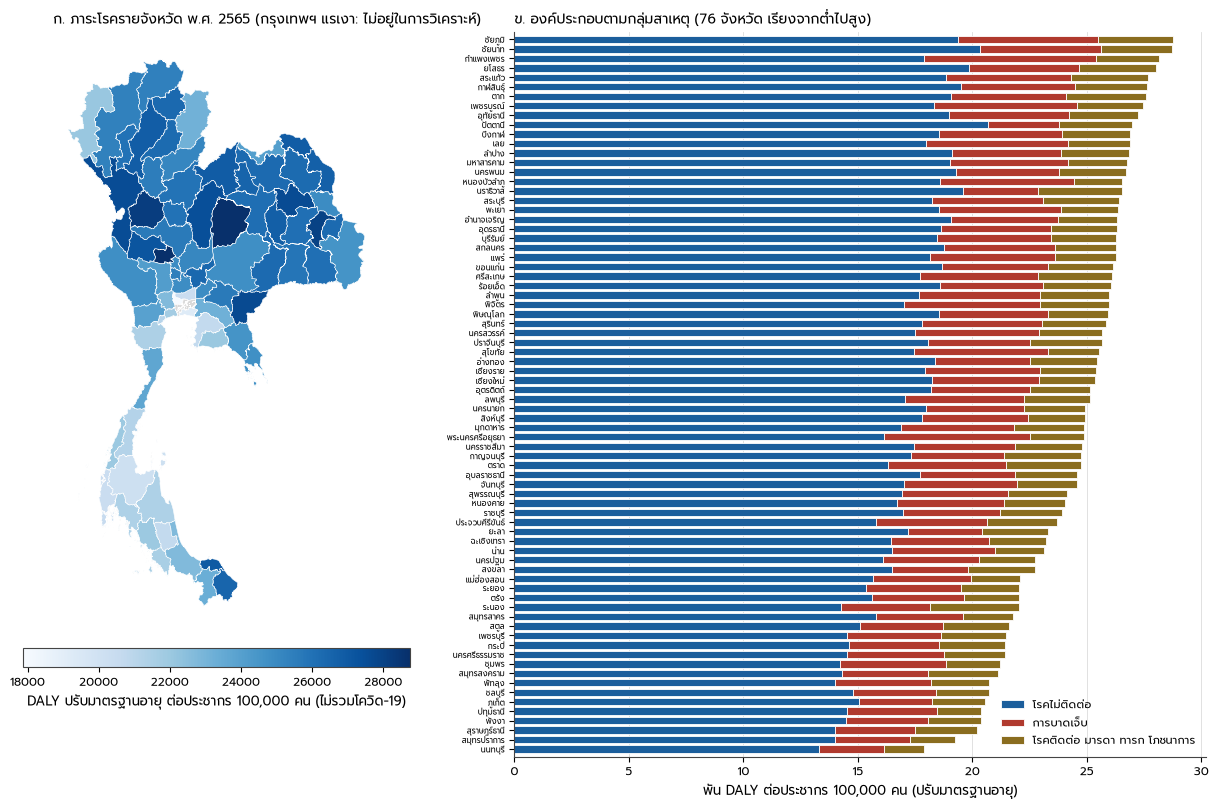

In [5]:
import geopandas as gpd
geo = gpd.read_file(C.ROOT / "output/map/geo_prov.geojson").rename(columns={"prov_id": "prov_code"})
geo["prov_code"] = geo.prov_code.astype(int)
geo = geo.merge(BW[["bod_daly"]].reset_index(), on="prov_code", how="left", validate="one_to_one")
fig, axes = plt.subplots(1, 2, figsize=(13, 8.2), gridspec_kw=dict(width_ratios=[1, 1.25]))
ax = axes[0]
g76 = geo[geo.prov_code != BK]
g76.plot(column="bod_daly", cmap="Blues", ax=ax, edgecolor="white", linewidth=0.4, legend=True,
         legend_kwds=dict(label="DALY ปรับมาตรฐานอายุ ต่อประชากร 100,000 คน (ไม่รวมโควิด-19)", orientation="horizontal",
                          shrink=0.7, pad=0.02))
geo[geo.prov_code == BK].plot(ax=ax, color="#d9d9d9", edgecolor="white", linewidth=0.4, hatch="///")
ax.set_axis_off()
ax.set_title("ก. ภาระโรครายจังหวัด พ.ศ. 2565 (กรุงเทพฯ แรเงา: ไม่อยู่ในการวิเคราะห์)", fontsize=10, loc="left")
ax = axes[1]
z = PROV.sort_values("bod_daly")
yy = np.arange(len(z))
left = np.zeros(len(z))
for g, col, lab in [("ncd", "#1b5e9c", "โรคไม่ติดต่อ"), ("inj", "#b03a2e", "การบาดเจ็บ"), ("cmnn", "#8a6d1f", "โรคติดต่อ มารดา ทารก โภชนาการ")]:
    ax.barh(yy, z[f"bod_daly_{g}"] / 1000, left=left, color=col, height=0.78, edgecolor="white", linewidth=0.6, label=lab)
    left += z[f"bod_daly_{g}"].to_numpy() / 1000
ax.set_yticks(yy)
ax.set_yticklabels(z.province, fontsize=5.6)
ax.set_xlabel("พัน DALY ต่อประชากร 100,000 คน (ปรับมาตรฐานอายุ)")
ax.grid(axis="x", color="#dcdcdc", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=False, fontsize=8)
ax.set_ylim(-0.8, len(z) - 0.2)
ax.set_title("ข. องค์ประกอบตามกลุ่มสาเหตุ (76 จังหวัด เรียงจากต่ำไปสูง)", fontsize=10, loc="left")
fig.tight_layout()
S.figure("F45_BOD_MAP", fig, TPROV, "ภาระโรคปรับมาตรฐานอายุรายจังหวัด พ.ศ. 2565 และองค์ประกอบตามกลุ่มสาเหตุ (ไม่รวมโควิด-19)", main=True)
plt.show()

## A5. ภาระโรคสัมพันธ์กับลักษณะใดของจังหวัด (สหสัมพันธ์ Spearman, ปี 2565)

In [6]:
panel, _ = P.province_panel()
p22 = panel[panel.year == BY].set_index("prov_code")
p25 = panel[panel.year == Y1].set_index("prov_code")
corr_vars = {"gpp_lag1": "GPP ต่อหัว (ปีก่อนหน้า)", "s3_60+": "สัดส่วนอายุ 60+", "s3_0-14": "สัดส่วนอายุ 0–14",
             "log_moph_physicians_per100k": "แพทย์ สธ. ต่อประชากร (log)", "log_all_sectors_physicians_per100k": "แพทย์ทุกสังกัดต่อประชากร (log)",
             "log_beds_moph_per1000": "เตียง สธ. ต่อประชากร (log)", "op_moph_pc": "ครั้ง OP ต่อคน", "adjrw_pc": "AdjRW ต่อคน"}
cr = []
for v, lab in corr_vars.items():
    for m in ["bod_daly", "bod_yll", "bod_yld"]:
        x = p22[v]
        ok = x.notna()
        rho, pv = spearmanr(x[ok], p22.loc[ok, m])
        cr.append(dict(variable=v, label_th=lab, measure=m, rho=rho, p_value=pv, n=int(ok.sum()), year=BY))
CR = pd.DataFrame(cr)
S.table("T45_BOD_CORRELATES", CR, "สหสัมพันธ์อันดับ (Spearman) ระหว่างภาระโรคปรับมาตรฐานอายุกับลักษณะจังหวัด ปี 2565 (76 จังหวัด)")
display(CR.pivot(index="label_th", columns="measure", values="rho").round(2))
for r in CR.itertuples():
    S.claim(f"c45_rho_{r.measure}_{r.variable}".replace("+", "plus").replace("-", "_"), r.rho, "{:+.2f}", "")

measure,bod_daly,bod_yld,bod_yll
label_th,,,
AdjRW ต่อคน,-0.15,0.18,-0.19
GPP ต่อหัว (ปีก่อนหน้า),-0.54,-0.34,-0.52
ครั้ง OP ต่อคน,0.11,0.24,0.02
สัดส่วนอายุ 0–14,-0.22,-0.32,-0.18
สัดส่วนอายุ 60+,0.15,0.30,0.10
เตียง สธ. ต่อประชากร (log),-0.13,-0.06,-0.13
แพทย์ สธ. ต่อประชากร (log),-0.30,0.06,-0.36
แพทย์ทุกสังกัดต่อประชากร (log),-0.51,-0.03,-0.57


## A6. อายุกับภาระโรค: ภาระรวมจริง ภาระส่วนเกิน และการสูงวัย
อัตราหยาบของจังหวัดเทียบประเทศแยกได้พอดีเป็นสองตัวคูณ (indirect standardization, อัตรารายอายุของ 76 จังหวัดรวมกันเป็นมาตรฐาน)

$\dfrac{\text{crude}_p}{\text{crude}_{76}}=\underbrace{\dfrac{\sum_a N_{pa} r^{76}_a}{N_p\,\text{crude}_{76}}}_{\text{โครงสร้างอายุ}}\times\underbrace{\dfrac{\text{DALY}_p}{\sum_a N_{pa} r^{76}_a}}_{\text{ภาระส่วนเกิน}}$

และภาระคาดหมายของแต่ละปี = ประชากรรายกลุ่มอายุของปีนั้น × อัตรารายอายุของจังหวัดปี 2565 (คงที่) ซึ่งแยกผลของขนาดและอายุของประชากรออกมา

In [7]:
ar = P.burden_age_rates()
ar76 = ar[ar.prov_code != BK]
nat_r = ar76.groupby("age_group")[["daly", "mid_pop"]].sum().pipe(lambda g: g.daly / g.mid_pop)
Npa = ar76.pivot(index="prov_code", columns="age_group", values="mid_pop")
Dp = ar76.groupby("prov_code").daly.sum()
Np = Npa.sum(1)
crude76 = Dp.sum() / Np.sum()
expected_nat = (Npa * nat_r).sum(1)
DEC = pd.DataFrame({"province": Dp.index.map(NAME), "daly_2022": Dp, "mid_pop_2022": Np, "crude_rate": 1e5 * Dp / Np,
                    "asr": BW.bod_daly.reindex(Dp.index), "age_factor": expected_nat / (Np * crude76), "excess_factor": Dp / expected_nat})
DEC["crude_relative"] = DEC.crude_rate / (1e5 * crude76)
assert np.allclose(DEC.crude_relative, DEC.age_factor * DEC.excess_factor)
DEC["share_60plus_of_daly"] = ar76[ar76.age_lo >= 60].groupby("prov_code").daly.sum() / Dp
lv = np.log(DEC[["crude_relative", "age_factor", "excess_factor"]])
var_age = (lv.age_factor.var() + lv.age_factor.cov(lv.excess_factor)) / lv.crude_relative.var()
DEC = DEC.reset_index().sort_values("crude_rate", ascending=False)
S.table("T45_BURDEN_AGE_DECOMPOSITION", DEC, "ภาระโรคหยาบรายจังหวัด ปี 2565 แยกเป็นผลของโครงสร้างอายุ × ภาระส่วนเกิน (มาตรฐาน = อัตรารายอายุของ 76 จังหวัด)", main=True)
display(DEC.head(8).round(3))
S.claim("c45_daly_total_76", Dp.sum(), "int", "DALY")
S.claim("c45_crude_76", 1e5 * crude76, "int", "DALY ต่อ 100,000")
S.claim("c45_crude_min", DEC.crude_rate.min(), "int", "DALY ต่อ 100,000")
S.claim("c45_crude_max", DEC.crude_rate.max(), "int", "DALY ต่อ 100,000")
S.text_claim("c45_crude_min_prov", DEC.sort_values("crude_rate").province.iloc[0])
S.text_claim("c45_crude_max_prov", DEC.sort_values("crude_rate").province.iloc[-1])
S.claim("c45_crude_asr_ratio_median", (DEC.crude_rate / DEC.asr).median(), "{:.2f}", "เท่า")
S.claim("c45_age_factor_min", DEC.age_factor.min(), "{:.2f}", "")
S.claim("c45_age_factor_max", DEC.age_factor.max(), "{:.2f}", "")
S.claim("c45_excess_min", DEC.excess_factor.min(), "{:.2f}", "")
S.claim("c45_excess_max", DEC.excess_factor.max(), "{:.2f}", "")
S.claim("c45_var_share_age", 100 * var_age, "{:.0f}", "%", note="(var(log age factor) + cov(log age, log excess)) / var(log crude relative)")
S.claim("c45_share60_daly", 100 * ar76[ar76.age_lo >= 60].daly.sum() / Dp.sum(), "{:.1f}", "%")
S.claim("c45_share60_pop", 100 * ar76[ar76.age_lo >= 60].mid_pop.sum() / Np.sum(), "{:.1f}", "%")
nat_rate_tab = pd.DataFrame({"age_group": nat_r.index, "age_lo": ar76.drop_duplicates("age_group").set_index("age_group").age_lo.reindex(nat_r.index).values,
                             "daly_per_person": nat_r.values})
S.claim("c45_rate_80_vs_30", nat_r.iloc[-1] / nat_r.loc[4], "{:.1f}", "เท่า", note="DALY per person aged 80+ / aged 30-44, 76 provinces")
# ageing at constant 2022 rates: civil register 2013-2025
EB = panel[["year", "prov_code", "population", "bod_daly_expected"]].groupby("year")[["population", "bod_daly_expected"]].sum()
S.claim("c45_expected_growth_1325", 100 * (EB.bod_daly_expected[Y1] / EB.bod_daly_expected[Y0] - 1), "{:.1f}", "%")
S.claim("c45_pop_growth_1325", 100 * (EB.population[Y1] / EB.population[Y0] - 1), "{:.1f}", "%")
S.claim("c45_expected_2025", EB.bod_daly_expected[Y1], "int", "DALY")
S.claim("c45_expected_2013", EB.bod_daly_expected[Y0], "int", "DALY")
gr = panel[panel.year.isin([Y0, Y1])].pivot_table(index="prov_code", columns="year", values="bod_daly_expected")
gr = 100 * (gr[Y1] / gr[Y0] - 1)
S.claim("c45_expected_growth_prov_min", gr.min(), "{:.1f}", "%")
S.claim("c45_expected_growth_prov_max", gr.max(), "{:.1f}", "%")
S.text_claim("c45_expected_growth_prov_max_name", NAME[gr.idxmax()])
print({k: round(v, 3) for k, v in dict(var_age=var_age, growth=EB.bod_daly_expected[Y1] / EB.bod_daly_expected[Y0]).items()})

/var/folders/y7/8_qm7_795fnd2fb2ztv5_j_w0000gn/T/ipykernel_53392/1371374946.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  Np = Npa.sum(1)
/var/folders/y7/8_qm7_795fnd2fb2ztv5_j_w0000gn/T/ipykernel_53392/1371374946.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  expected_nat = (Npa * nat_r).sum(1)


,prov_code,province,daly_2022,mid_pop_2022,crude_rate,asr,age_factor,excess_factor,crude_relative,share_60plus_of_daly
7,18,ชัยนาท,128786.010,319015.0,40369.892,28708.058,1.137,1.148,1.305,0.499
39,52,ลำปาง,279412.115,718966.0,38863.050,26846.679,1.153,1.090,1.256,0.542
41,54,แพร่,165236.523,431977.0,38251.232,26275.526,1.139,1.086,1.237,0.540
38,51,ลำพูน,148125.658,397303.0,37282.794,25980.331,1.127,1.069,1.205,0.539
6,17,สิงห์บุรี,75567.531,203368.0,37158.024,24897.482,1.158,1.038,1.201,0.544
43,56,พะเยา,170415.927,460520.0,37005.109,26357.576,1.097,1.091,1.196,0.522
47,61,อุทัยธานี,118845.039,324019.0,36678.417,27212.792,1.075,1.103,1.186,0.467
23,36,ชัยภูมิ,409127.013,1118897.0,36565.208,28745.435,1.031,1.147,1.182,0.450


{'var_age': np.float64(0.367), 'growth': np.float64(1.211)}


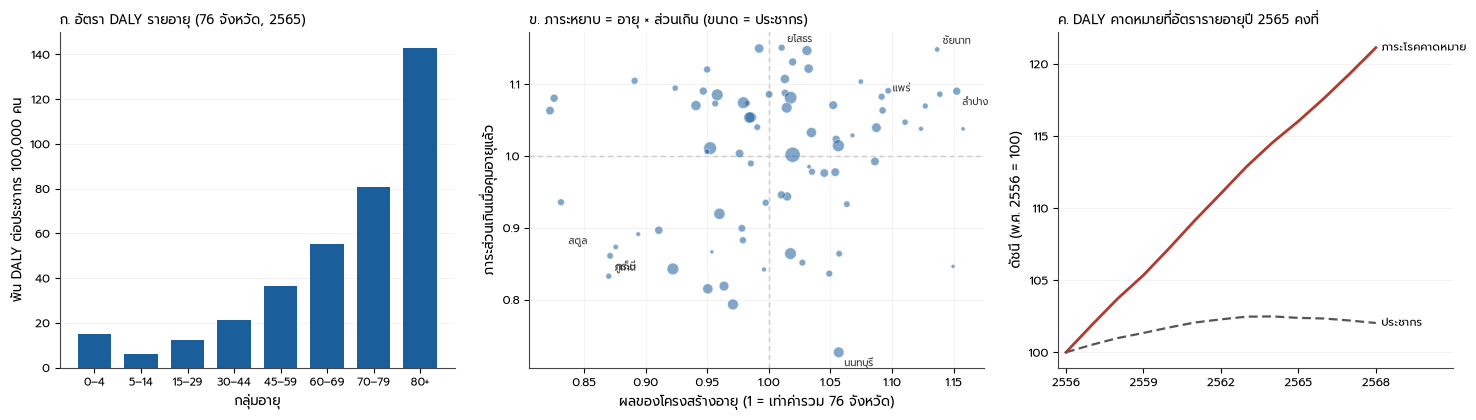

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw=dict(width_ratios=[1, 1.15, 1]))
ax = axes[0]
labs8 = ["0–4", "5–14", "15–29", "30–44", "45–59", "60–69", "70–79", "80+"]
ax.bar(range(8), 1e5 * nat_r.values / 1000, color="#1b5e9c", width=0.72)
ax.set_xticks(range(8)); ax.set_xticklabels(labs8, fontsize=8)
ax.set_xlabel("กลุ่มอายุ"); ax.set_ylabel("พัน DALY ต่อประชากร 100,000 คน")
ax.set_title("ก. อัตรา DALY รายอายุ (76 จังหวัด, 2565)", fontsize=9.5, loc="left")
ax.grid(axis="y", color="#eeeeee", linewidth=0.5); ax.set_axisbelow(True)
ax = axes[1]
z = DEC.set_index("prov_code")
ax.scatter(z.age_factor, z.excess_factor, s=z.mid_pop_2022 / 2.2e4, color="#1b5e9c", alpha=0.55, edgecolor="white", linewidth=0.6, zorder=3)
ax.axhline(1, **R.REFLINE_KW); ax.axvline(1, **R.REFLINE_KW)
lab_ = pd.concat([z.nlargest(3, "crude_rate"), z.nsmallest(3, "crude_rate"), z.nlargest(1, "excess_factor"), z.nsmallest(1, "excess_factor")])
for i, (pc, r) in enumerate(lab_[~lab_.index.duplicated()].iterrows()):
    ax.annotate(r.province, (r.age_factor, r.excess_factor), fontsize=7, xytext=[(4, 4), (4, -10), (-34, 2)][i % 3],
                textcoords="offset points", color="#333")
ax.set_xlabel("ผลของโครงสร้างอายุ (1 = เท่าค่ารวม 76 จังหวัด)")
ax.set_ylabel("ภาระส่วนเกินเมื่อคุมอายุแล้ว")
ax.set_title("ข. ภาระหยาบ = อายุ × ส่วนเกิน (ขนาด = ประชากร)", fontsize=9.5, loc="left")
ax.grid(color="#eeeeee", linewidth=0.5, zorder=0)
ax = axes[2]
ix_ = EB / EB.loc[Y0] * 100
ax.plot(ix_.index, ix_.bod_daly_expected, color="#b03a2e", lw=2)
ax.plot(ix_.index, ix_.population, color="#555555", lw=1.6, ls=(0, (4, 2)))
ax.annotate("ภาระโรคคาดหมาย", (Y1, ix_.bod_daly_expected[Y1]), xytext=(4, 0), textcoords="offset points", fontsize=8, va="center")
ax.annotate("ประชากร", (Y1, ix_.population[Y1]), xytext=(4, 0), textcoords="offset points", fontsize=8, va="center")
R.be_ticks(ax, list(range(Y0, Y1 + 1)), step=3)
ax.set_xlim(Y0 - 0.3, Y1 + 3)
ax.set_ylabel(f"ดัชนี (พ.ศ. {C.be(Y0)} = 100)")
ax.set_title("ค. DALY คาดหมายที่อัตรารายอายุปี 2565 คงที่", fontsize=9.5, loc="left")
ax.grid(axis="y", color="#eeeeee", linewidth=0.5)
fig.tight_layout()
S.figure("F45_AGE_BURDEN", fig, DEC, "อายุกับภาระโรค: อัตรา DALY รายอายุ, การแยกภาระหยาบเป็นผลของอายุและภาระส่วนเกิน และภาระคาดหมายตามการสูงวัย 2556–2568", main=True)
plt.show()

---
# ส่วน B — ความชุกที่บันทึกกับภาระโรคที่ประมาณการ
ถ้าความชุกใน HDC สะท้อนความจำเป็น จังหวัดที่มีภาระโรคนั้นสูงควรมีความชุกที่บันทึกสูงด้วย
ถ้าสะท้อนการเข้าถึงการวินิจฉัย ความชุกที่บันทึกจะสัมพันธ์กับทรัพยากรมากกว่าภาระโรค

จับคู่ตัวชี้วัด HDC กับกลุ่มโรค BOD ที่ใกล้ที่สุด (ความดันโลหิตสูงเป็นปัจจัยเสี่ยง ไม่ใช่กลุ่มโรคใน BOD จึงจับคู่กับ I4 โรคหัวใจจากความดันโลหิตสูง และต้องอ่านอย่างระวัง)
ใช้ YLD เป็นตัวเทียบหลักเพราะใกล้กับ "การมีชีวิตอยู่กับโรค" มากที่สุด และใช้ปี 2565 ทั้งสองแหล่ง

แบบจำลองการบันทึก: $\log \text{prev}^{HDC}_{pc}=\alpha_c+\beta\log \text{YLD}^{BOD}_{pc}+\gamma\log(\text{แพทย์}/\text{ประชากร})_p+\delta'\text{อายุ}_p+\varepsilon$
ความชุก HDC ไม่ปรับอายุ แต่ YLD ปรับแล้ว จึงต้องคุมสัดส่วนอายุ ค่า γ > 0 หมายถึงที่ภาระโรคเท่ากัน จังหวัดที่มีแพทย์มากกว่าบันทึกโรคได้มากกว่า
— สอดคล้องกับการวินิจฉัยที่ขึ้นกับทรัพยากร (ไม่ใช่หลักฐานเชิงเหตุผล)

In [9]:
HM = BC["hdc_match"]
HM_TH = {"prev_dm": "เบาหวาน – O1 เบาหวาน", "prev_ht": "ความดันโลหิตสูง – I4 โรคหัวใจจากความดันฯ", "prev_ckd_3_5": "ไตเรื้อรังระยะ 3–5 – O2 ไตเรื้อรัง",
         "prev_copd": "ปอดอุดกั้นเรื้อรัง – J1 COPD", "prev_stroke": "หลอดเลือดสมอง – I3 หลอดเลือดสมอง", "prev_chd": "หลอดเลือดหัวใจ – I2 หัวใจขาดเลือด"}
rv = []
stack = []
for ind, cause in HM.items():
    z = p22[[ind, f"bod_yld_{ind}", f"bod_daly_{ind}", "log_moph_physicians_per100k", "log_beds_moph_per1000", "s3_60+", "s3_0-14", "population"]].dropna()
    z = z[(z[ind] > 0) & (z[f"bod_yld_{ind}"] > 0)]
    r_yld = spearmanr(z[ind], z[f"bod_yld_{ind}"])
    r_daly = spearmanr(z[ind], z[f"bod_daly_{ind}"])
    # recorded-to-modeled ratio (relative to the 76-province median of the ratio) and its association with physicians
    ratio = np.log(z[ind]) - np.log(z[f"bod_yld_{ind}"])
    r_phys = spearmanr(ratio, z.log_moph_physicians_per100k)
    X = sm.add_constant(pd.DataFrame({"log_bod_yld": np.log(z[f"bod_yld_{ind}"]), "log_phys": z.log_moph_physicians_per100k,
                                      "s60": z["s3_60+"], "s014": z["s3_0-14"]}))
    f = sm.OLS(np.log(z[ind]), X).fit(cov_type="HC3")
    rv.append(dict(indicator=ind, pair_th=HM_TH[ind], bod_cause=cause, n=len(z), rho_prev_yld=r_yld.statistic, p_prev_yld=r_yld.pvalue,
                   rho_prev_daly=r_daly.statistic, rho_ratio_physicians=r_phys.statistic, p_ratio_physicians=r_phys.pvalue,
                   beta_log_yld=f.params["log_bod_yld"], beta_lo=f.conf_int().loc["log_bod_yld", 0], beta_hi=f.conf_int().loc["log_bod_yld", 1],
                   gamma_log_phys=f.params["log_phys"], gamma_lo=f.conf_int().loc["log_phys", 0], gamma_hi=f.conf_int().loc["log_phys", 1],
                   r2=f.rsquared, year=BY))
    stack.append(z.assign(indicator=ind, log_prev=np.log(z[ind]), log_bod_yld=np.log(z[f"bod_yld_{ind}"])).reset_index())
RV = pd.DataFrame(rv)
S.table("T45_RECORDED_VS_MODELED", RV, "ความชุกที่วินิจฉัยแล้วใน HDC เทียบภาระโรคที่ประมาณการ (BOD) รายโรค ปี 2565: สหสัมพันธ์ และแบบจำลองการบันทึก (OLS, HC3)", main=True)
display(RV.round(3))
for r in RV.itertuples():
    S.claim(f"c45_rho_rec_{r.indicator}", r.rho_prev_yld, "{:+.2f}", "")
    S.claim(f"c45_rho_ratio_phys_{r.indicator}", r.rho_ratio_physicians, "{:+.2f}", "")
S.claim("c45_rho_rec_min", RV.rho_prev_yld.min(), "{:+.2f}", "")
S.claim("c45_rho_rec_max", RV.rho_prev_yld.max(), "{:+.2f}", "")
S.claim("c45_n_rec_weak", int((RV.rho_prev_yld.abs() < 0.3).sum()), "int", "โรค", note="|rho| < 0.3")

# pooled across the six conditions: condition fixed effects, province-clustered inference
ST = pd.concat(stack, ignore_index=True)
Xp = pd.concat([ST[["log_bod_yld", "log_moph_physicians_per100k", "s3_60+", "s3_0-14"]].rename(
    columns={"log_moph_physicians_per100k": "log_phys", "s3_60+": "s60", "s3_0-14": "s014"}),
    pd.get_dummies(ST.indicator, prefix="c", drop_first=True, dtype=float)], axis=1)
Xp = sm.add_constant(Xp)
pool = []
for spec, cols_ in [("burden_only", ["const", "log_bod_yld"] + [c for c in Xp if c.startswith("c_")]),
                    ("burden_age", ["const", "log_bod_yld", "s60", "s014"] + [c for c in Xp if c.startswith("c_")]),
                    ("burden_age_physicians", ["const", "log_bod_yld", "s60", "s014", "log_phys"] + [c for c in Xp if c.startswith("c_")])]:
    f = sm.OLS(ST.log_prev, Xp[cols_]).fit(cov_type="cluster", cov_kwds={"groups": ST.prov_code})
    for t in ["log_bod_yld", "log_phys", "s60"]:
        if t in f.params:
            ci = f.conf_int().loc[t]
            pool.append(dict(spec=spec, term=t, coef=f.params[t], lo95=ci[0], hi95=ci[1], p_value=f.pvalues[t], n=int(f.nobs),
                             clusters=ST.prov_code.nunique(), r2_within_condition=np.nan))
POOL = pd.DataFrame(pool)
S.table("T45_RECORDING_MODEL_POOLED", POOL, "แบบจำลองการบันทึกแบบรวมหกโรค (ผลคงที่รายโรค, ช่วงเชื่อมั่นแบบ cluster จังหวัด): log ความชุก HDC ~ log YLD BOD + อายุ + log แพทย์ต่อประชากร")
display(POOL.round(3))
g = POOL[(POOL.spec == "burden_age_physicians") & (POOL.term == "log_phys")].iloc[0]
S.claim("c45_rec_gamma", g.coef, "{:.2f}", "", note="elasticity of recorded prevalence wrt MOPH physician density, given modeled burden and age")
S.claim("c45_rec_gamma_lo", g.lo95, "{:.2f}", "")
S.claim("c45_rec_gamma_hi", g.hi95, "{:.2f}", "")
S.claim("c45_rec_gamma_10pct", 100 * (1.1 ** g.coef - 1), "{:.1f}", "%", note="% change in recorded prevalence for +10% physician density")
bb = POOL[(POOL.spec == "burden_age_physicians") & (POOL.term == "log_bod_yld")].iloc[0]
S.claim("c45_rec_beta", bb.coef, "{:.2f}", "")
S.claim("c45_rec_beta_lo", bb.lo95, "{:.2f}", "")
S.claim("c45_rec_beta_hi", bb.hi95, "{:.2f}", "")
S.text_claim("c45_rec_gamma_sign", "บวกและช่วงเชื่อมั่นไม่คร่อมศูนย์" if g.lo95 > 0 else ("ลบและช่วงเชื่อมั่นไม่คร่อมศูนย์" if g.hi95 < 0 else "ช่วงเชื่อมั่นคร่อมศูนย์"))

,indicator,pair_th,bod_cause,n,rho_prev_yld,p_prev_yld,rho_prev_daly,rho_ratio_physicians,p_ratio_physicians,beta_log_yld,beta_lo,beta_hi,gamma_log_phys,gamma_lo,gamma_hi,r2,year
0,prev_dm,เบาหวาน – O1 เบาหวาน,O1,76,-0.039,0.735,-0.026,0.323,0.004,0.116,-0.045,0.278,0.017,-0.143,0.177,0.741,2022
1,prev_ht,ความดันโลหิตสูง – I4 โรคหัวใจจากความดันฯ,I4,76,-0.064,0.585,0.067,0.232,0.044,-0.004,-0.037,0.029,0.149,0.045,0.253,0.821,2022
2,prev_ckd_3_5,ไตเรื้อรังระยะ 3–5 – O2 ไตเรื้อรัง,O2,75,0.386,0.001,0.430,0.398,0.000,0.548,0.346,0.749,-0.045,-0.323,0.234,0.659,2022
3,prev_copd,ปอดอุดกั้นเรื้อรัง – J1 COPD,J1,75,0.394,0.000,0.416,0.143,0.219,0.237,-0.054,0.528,0.076,-0.480,0.632,0.325,2022
4,prev_stroke,หลอดเลือดสมอง – I3 หลอดเลือดสมอง,I3,76,0.214,0.064,0.194,0.307,0.007,1.283,-0.027,2.592,0.801,-0.484,2.086,0.210,2022
5,prev_chd,หลอดเลือดหัวใจ – I2 หัวใจขาดเลือด,I2,76,0.239,0.037,0.023,0.202,0.081,0.369,-0.040,0.777,0.689,-0.743,2.122,0.212,2022


,spec,term,coef,lo95,hi95,p_value,n,clusters,r2_within_condition
0,burden_only,log_bod_yld,0.192,0.078,0.306,0.001,454,76,NaN
1,burden_age,log_bod_yld,0.204,0.104,0.303,0.000,454,76,NaN
2,burden_age,s60,6.202,2.239,10.164,0.002,454,76,NaN
3,burden_age_physicians,log_bod_yld,0.204,0.108,0.299,0.000,454,76,NaN
4,burden_age_physicians,log_phys,0.356,-0.048,0.761,0.084,454,76,NaN
5,burden_age_physicians,s60,3.909,-1.537,9.356,0.159,454,76,NaN


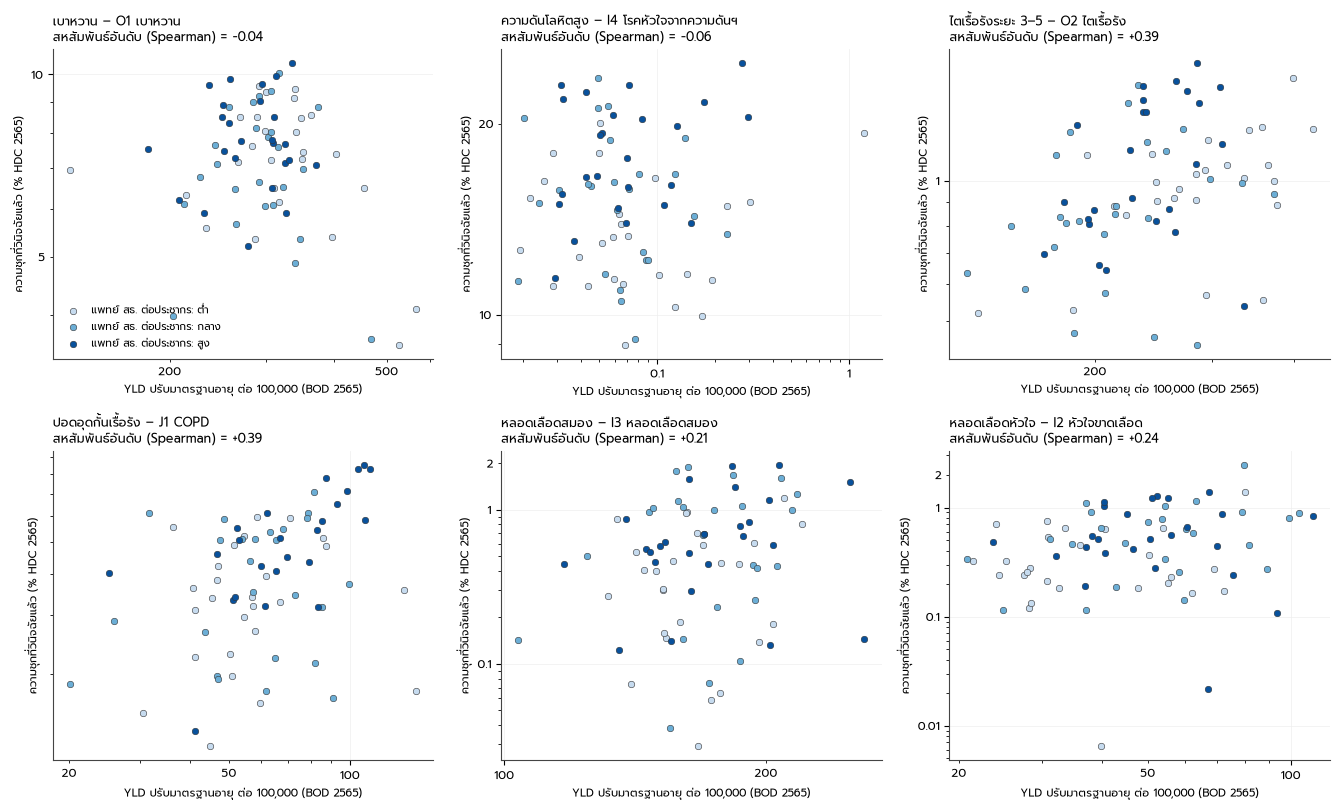

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.2))
dens_t = pd.qcut(p22.log_moph_physicians_per100k, 3, labels=["ต่ำ", "กลาง", "สูง"])
tcol = {"ต่ำ": "#c6dbef", "กลาง": "#6baed6", "สูง": "#08519c"}
for ax, (ind, cause) in zip(axes.ravel(), HM.items()):
    z = ST[ST.indicator == ind]
    for t in ["ต่ำ", "กลาง", "สูง"]:
        m = dens_t.reindex(z.prov_code).to_numpy() == t
        ax.scatter(z.loc[m, f"bod_yld_{ind}"], z.loc[m, ind], s=22, color=tcol[t], edgecolor="#333", linewidth=0.4, label=f"แพทย์ สธ. ต่อประชากร: {t}", zorder=3)
    ax.set_xscale("log"); ax.set_yscale("log")
    for a_ in (ax.xaxis, ax.yaxis):
        a_.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
        a_.set_minor_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}" if f"{v:g}"[0] in "25" else ""))
    r = RV.set_index("indicator").loc[ind]
    ax.set_title(f"{HM_TH[ind]}\nสหสัมพันธ์อันดับ (Spearman) = {r.rho_prev_yld:+.2f}", fontsize=9, loc="left")
    ax.set_xlabel("YLD ปรับมาตรฐานอายุ ต่อ 100,000 (BOD 2565)", fontsize=8)
    ax.set_ylabel("ความชุกที่วินิจฉัยแล้ว (% HDC 2565)", fontsize=8)
    ax.grid(color="#eeeeee", linewidth=0.5, zorder=0)
axes[0, 0].legend(frameon=False, fontsize=7.5, loc="best")
fig.tight_layout()
S.figure("F45_RECORDED_VS_MODELED", fig, ST[["prov_code", "indicator", "log_prev", "log_bod_yld", "log_moph_physicians_per100k"]],
         "ความชุกที่วินิจฉัยแล้วใน HDC เทียบภาระโรคที่ประมาณการ (YLD, BOD) รายโรค ปี 2565 สีตามความหนาแน่นแพทย์ สธ.", main=True)
plt.show()

---
# ส่วน C — ภาระโรคช่วยทำนายบริการหรือไม่
ตัวอย่างร่วม fold และวิธีวัดเดียวกับ M0–M5 ของ 4.2.3 (ตรวจว่า fold ตรงกับ T423_FOLD_ASSIGNMENT)
ภาระโรคเป็นค่าคงที่รายจังหวัด จึงอธิบายได้เฉพาะความต่าง **ระหว่างจังหวัด**

| แบบ | ตัวแปร |
|---|---|
| M1 | ปี + อายุ |
| M2 | M1 + ความชุกที่บันทึก (HDC) |
| M2B | M1 + log DALY รวม (BOD) |
| M2B3 | M1 + log DALY แยก CMNN / NCD / บาดเจ็บ |
| M2HB | M2 + log DALY รวม |
| M5 | อายุ ความชุก GPP เตียง แพทย์ พยาบาล |
| M5B | M5 โดยใช้ภาระโรคแทนความชุกที่บันทึก |
| M5HB | M5 + log DALY รวม |

In [11]:
MC = C.CFG["models"]
OUT = MC["outcomes"]
OUT_TH = {"op_moph": "ครั้งผู้ป่วยนอก", "ip_moph": "วันนอนรวม", "adjrw": "ผลรวม AdjRW"}
Z = panel[panel.elig_m5_common].reset_index(drop=True)
assert Z[P.BURDEN + P.BURDEN_GROUPS].notna().all().all()
FOLDS = MD.province_folds(Z.prov_code.unique(), MC["cv_folds"], MC["cv_repeats"], MC["cv_seed"])
F42 = pd.read_csv(T42 / "T423_FOLD_ASSIGNMENT.csv", encoding="utf-8-sig")
same = FOLDS.merge(F42, on=["repeat", "prov_code"], suffixes=("", "_42"))
assert len(same) == len(FOLDS) and (same.fold == same.fold_42).all(), "folds differ from 4.2 - comparison would not be paired"
FULL = ["age", "disease", "gpp", "beds", "physicians", "nurses"]
SUPPLY = ["gpp", "beds", "physicians", "nurses"]
SPECS = {"M1": ["age"], "M2": ["age", "disease"], "M2B": ["age", "bod"], "M2B3": ["age", "bod3"], "M2HB": ["age", "disease", "bod"],
         "M5": FULL, "M5B": ["age", "bod"] + SUPPLY, "M5HB": FULL + ["bod"]}
PRED = pd.concat([MD.cross_validate(Z, o, SPECS, FOLDS, age_k=3) for o in OUT], ignore_index=True)
SC = MD.score(PRED)
# reconcile with 4.2: M1, M2 and M5 must reproduce the published R2 exactly (same rows, folds, estimator)
SC42 = pd.read_csv(T42 / "T423_MODEL_VALIDATION.csv", encoding="utf-8-sig")
rec = SC.merge(SC42, on=["outcome", "model", "estimator", "age_groups"], suffixes=("", "_42"))
assert np.allclose(rec.r2_pred_train_mean, rec.r2_pred_train_mean_42), "CV does not reproduce T423_MODEL_VALIDATION"
S.claim("c45_cv_repro_max_gap", float((rec.r2_pred_train_mean - rec.r2_pred_train_mean_42).abs().max()), "{:.1e}", "")
S.table("T45_MODEL_VALIDATION_BURDEN", SC, "R² นอกตัวอย่างของแบบจำลองที่ใช้ภาระโรค (fold และตัวอย่างเดียวกับ 4.2.3)", main=True)
display(SC.pivot(index="model", columns="outcome", values="r2_pred_train_mean").reindex(list(SPECS)).round(3))
for r in SC.itertuples():
    S.claim(f"c45_r2_{r.outcome}_{r.model}", r.r2_pred_train_mean, "{:.3f}", "")
PAIRS = [("M1", "M2"), ("M1", "M2B"), ("M1", "M2B3"), ("M2", "M2HB"), ("M2", "M2B"), ("M5", "M5B"), ("M5", "M5HB")]
GAINS = MD.paired_gains(PRED, PAIRS, MC["paired_bootstrap_draws"], MC["cv_seed"] + 4501)
S.table("T45_PAIRED_GAINS_BURDEN", GAINS, "การลดลงของความคลาดเคลื่อนกำลังสองนอกตัวอย่าง (%) เมื่อเพิ่มหรือแทนด้วยภาระโรค พร้อมช่วง 95% (bootstrap จังหวัด)", main=True)
display(GAINS.pivot_table(index=["baseline", "model"], columns="outcome", values=["sse_reduction_pct", "lo95", "hi95"]).round(2))
for r in GAINS.itertuples():
    tag = f"{r.outcome}_{r.baseline}_{r.model}"
    S.claim(f"c45_gain_{tag}", r.sse_reduction_pct, "{:.2f}", "%")
    S.claim(f"c45_gainlo_{tag}", r.lo95, "{:.2f}", "%")
    S.claim(f"c45_gainhi_{tag}", r.hi95, "{:.2f}", "%")
sig = GAINS[(GAINS.lo95 > 0)]
S.text_claim("c45_gain_significant", "; ".join(f"{OUT_TH[r.outcome]} {r.baseline}→{r.model}" for r in sig.itertuples()) or "ไม่มี")
S.claim("c45_gain_significant_n", len(sig), "int", "คู่")

# coefficients of log burden (province-clustered), in-sample on the common rows
co = []
for o in OUT:
    y = Z[MD.RATE_COL[o]].to_numpy(float)
    for m in ["M2B", "M2HB", "M5HB"]:
        X, nm = MD.design(Z, o, SPECS[m], years=sorted(Z.year.unique()))
        t = MD.cluster_ols(X, y, Z.prov_code.to_numpy(), nm)
        t = t[t.term.str.startswith("log_bod")].assign(outcome=o, model=m, mean_outcome=y.mean())
        co.append(t)
CO = pd.concat(co, ignore_index=True)
CO["pct_outcome_per_10pct_burden"] = 100 * CO.coef * np.log(1.1) / CO.mean_outcome
S.table("T45_BURDEN_COEFFICIENTS", CO, "สัมประสิทธิ์ของ log ภาระโรคในแบบจำลองบริการ (OLS, ช่วง 95% แบบ cluster จังหวัด) — ความสัมพันธ์เชิงทำนาย ไม่ใช่เชิงเหตุผล")
display(CO.round(4))
for r in CO[CO.model == "M5HB"].itertuples():
    S.claim(f"c45_coef_pct10_{r.outcome}", r.pct_outcome_per_10pct_burden, "{:+.1f}", "%")
    S.claim(f"c45_coef_pct10_{r.outcome}_lo", 100 * r.lo95 * np.log(1.1) / r.mean_outcome, "{:+.1f}", "%")
    S.claim(f"c45_coef_pct10_{r.outcome}_hi", 100 * r.hi95 * np.log(1.1) / r.mean_outcome, "{:+.1f}", "%")

outcome,adjrw,ip_moph,op_moph
model,,,
M1,0.013,0.282,0.301
M2,0.190,0.312,0.263
M2B,-0.053,0.244,0.260
M2B3,-0.131,0.257,0.253
M2HB,0.185,0.315,0.238
M5,0.511,0.592,0.462
M5B,0.487,0.592,0.492
M5HB,0.488,0.590,0.450


hi95                   lo95                 sse_reduction_pct                
outcome         adjrw ip_moph op_moph  adjrw ip_moph op_moph             adjrw ip_moph op_moph
baseline model                                                                                
M1       M2     38.37   15.12    4.22 -13.51   -9.35  -16.20             17.95    4.24   -5.42
         M2B    -3.08   -1.11   -0.70 -11.29  -10.53  -11.83             -6.67   -5.18   -5.76
         M2B3   -5.90    2.77    1.03 -23.91   -9.79  -14.62            -14.59   -3.47   -6.85
M2       M2B     7.30    5.96    9.46 -75.86  -27.50  -10.93            -30.01   -9.84   -0.32
         M2HB    4.54    5.43   -0.49  -8.10   -5.42   -6.63             -0.64    0.35   -3.39
M5       M5B    18.14    5.01   13.86 -26.19   -4.71   -3.68             -4.90    0.00    5.51
         M5HB   -1.34    1.92   -0.94  -8.02   -3.86   -3.51             -4.55   -0.63   -2.18

,term,coef,se,lo95,hi95,outcome,model,mean_outcome,pct_outcome_per_10pct_burden
0,log_bod_daly,-0.1502,0.6251,-1.3954,1.0950,op_moph,M2B,2.4205,-0.5913
1,log_bod_daly,-0.3228,0.5677,-1.4538,0.8082,op_moph,M2HB,2.4205,-1.2710
2,log_bod_daly,0.1956,0.4707,-0.7421,1.1332,op_moph,M5HB,2.4205,0.7701
3,log_bod_daly,-0.0213,0.1329,-0.2861,0.2435,ip_moph,M2B,0.5800,-0.3500
4,log_bod_daly,-0.2042,0.1104,-0.4240,0.0157,ip_moph,M2HB,0.5800,-3.3553
5,log_bod_daly,-0.1010,0.0720,-0.2443,0.0424,ip_moph,M5HB,0.5800,-1.6593
6,log_bod_daly,0.0130,0.0549,-0.0964,0.1224,adjrw,M2B,0.1704,0.7272
7,log_bod_daly,-0.0593,0.0475,-0.1540,0.0355,adjrw,M2HB,0.1704,-3.3153
8,log_bod_daly,0.0074,0.0401,-0.0725,0.0872,adjrw,M5HB,0.1704,0.4116


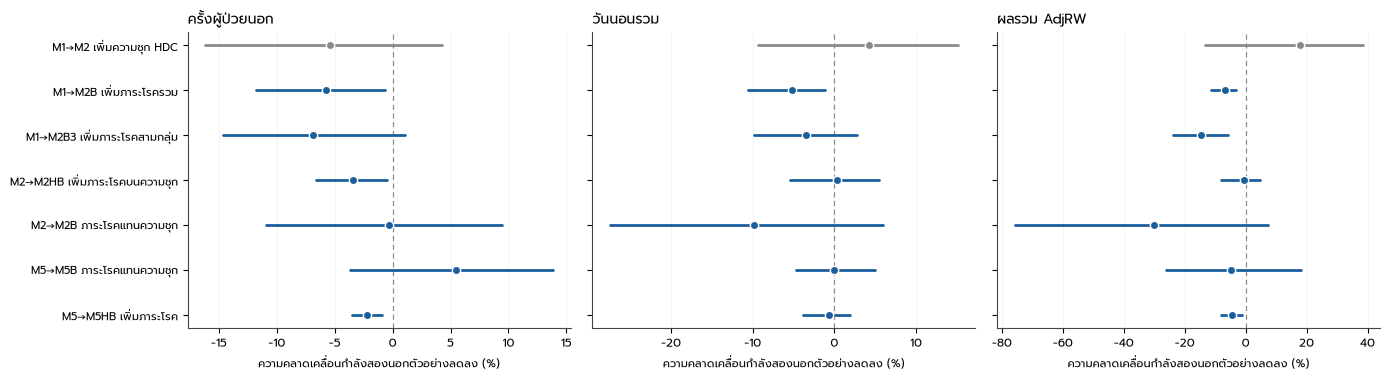

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
lab = {("M1", "M2"): "M1→M2 เพิ่มความชุก HDC", ("M1", "M2B"): "M1→M2B เพิ่มภาระโรครวม", ("M1", "M2B3"): "M1→M2B3 เพิ่มภาระโรคสามกลุ่ม",
       ("M2", "M2HB"): "M2→M2HB เพิ่มภาระโรคบนความชุก", ("M2", "M2B"): "M2→M2B ภาระโรคแทนความชุก",
       ("M5", "M5B"): "M5→M5B ภาระโรคแทนความชุก", ("M5", "M5HB"): "M5→M5HB เพิ่มภาระโรค"}
for ax, o in zip(axes, OUT):
    z = GAINS[GAINS.outcome == o].reset_index(drop=True)
    yy = np.arange(len(z))[::-1]
    ax.axvline(0, color="#8a8a8a", lw=0.9, ls=(0, (4, 3)))
    for y_, r in zip(yy, z.itertuples()):
        col = "#1b5e9c" if "B" in r.model else "#8a8a8a"
        ax.plot([r.lo95, r.hi95], [y_, y_], color=col, lw=2, solid_capstyle="round")
        ax.plot(r.sse_reduction_pct, y_, "o", color=col, ms=6, mec="white", mew=1)
    ax.set_yticks(yy)
    ax.set_yticklabels([lab[(r.baseline, r.model)] for r in z.itertuples()], fontsize=8)
    ax.set_title(OUT_TH[o], fontsize=10, loc="left")
    ax.set_xlabel("ความคลาดเคลื่อนกำลังสองนอกตัวอย่างลดลง (%)", fontsize=8)
    ax.grid(axis="x", color="#eeeeee", linewidth=0.5)
fig.tight_layout()
S.figure("F45_MODEL_GAINS", fig, GAINS, "ภาระโรคช่วยทำนายบริการเพิ่มหรือไม่: การลดลงของความคลาดเคลื่อนนอกตัวอย่างพร้อมช่วง 95% (fold เดียวกับ 4.2.3)", main=True)
plt.show()

---
# ส่วน D — กำลังคนกระจายตามภาระโรคหรือไม่
## D1. ตัวหารที่ถ่วงภาระโรค
ดัชนีภาระสัมพัทธ์ $RB_p=\text{DALY}^{ASR}_p\big/\big(\sum_q N_{qt}\text{DALY}^{ASR}_q/\sum_q N_{qt}\big)$ (76 จังหวัด) แล้ว

* **bod_pop** = ประชากร × RB — ประชากรถ่วงภาระโรคส่วนเกินที่ไม่เกี่ยวกับอายุ
* **bod_count** = DALY คาดหมาย = ประชากรรายกลุ่มอายุของปีนั้น × อัตรา DALY รายอายุของจังหวัดปี 2565 — ภาระรวมจริงที่จังหวัดรับผิดชอบ (อายุ + ส่วนเกิน)
* **bod_yld_count** = YLD คาดหมายแบบเดียวกัน (ภาระการเจ็บป่วย ซึ่งใกล้กับความต้องการบริการมากกว่าการตาย)
* **bod_allcause_pop** = ประชากร × RB ทุกสาเหตุรวมโควิด-19 (ความไว)

ตัวหารแบบ RB มีผลรวมเท่ากับประชากรรวมทุกปี ส่วนตัวหารแบบนับ (count) มีหน่วยเป็น DALY/YLD ดัชนีความเหลื่อมล้ำและอันดับขึ้นกับส่วนแบ่งเท่านั้น หน่วยจึงไม่มีผล
อัตรา (ASR หรืออัตรารายอายุ) ถูกตรึงที่ปี 2565 (มีปีเดียว) เมื่อใช้กับปีอื่น

In [13]:
WF = pd.concat([P.workforce_province(u).assign(scope=u) for u in ["all_sectors", "moph"]])
WF = WF[WF.prov_code != BK].rename(columns={"headcount": "W"})
pp = panel[["year", "prov_code", "population"]].copy()
aw = AWP[(AWP.scheme == "scenario_moderate") & (AWP.prov_code != BK)][["year", "prov_code", "age_weighted_pop"]]
pp = pp.merge(aw, on=["year", "prov_code"], how="left", validate="one_to_one")
for m, col in [("daly", "bod_daly"), ("yld", "bod_yld"), ("allcause", "bod_daly_allcause"), ("yll", "bod_yll")]:
    pp[f"asr_{m}"] = pp.prov_code.map(BW[col])
    pp[f"RB_{m}"] = pp[f"asr_{m}"] / pp.groupby("year").apply(lambda g: (g.population * g[f"asr_{m}"]).sum() / g.population.sum(),
                                                                 include_groups=False).reindex(pp.year).to_numpy()
pp = pp.merge(panel[["year", "prov_code", "bod_daly_expected", "bod_yld_expected"]], on=["year", "prov_code"], validate="one_to_one")
den = {"population": pp.population, "age_scenario_moderate": pp.age_weighted_pop,
       "bod_pop": pp.population * pp.RB_daly, "bod_count": pp.bod_daly_expected,
       "bod_yld_count": pp.bod_yld_expected, "bod_allcause_pop": pp.population * pp.RB_allcause}
DEN = pd.concat([pp[["year", "prov_code"]].assign(denominator=k, D=v.to_numpy()) for k, v in den.items()], ignore_index=True).dropna()
assert (DEN.D > 0).all()
chk = DEN[DEN.denominator.isin(["population", "bod_pop", "bod_allcause_pop"])].groupby(["year", "denominator"]).D.sum().unstack()
assert np.allclose(chk.bod_pop, chk.population) and np.allclose(chk.bod_allcause_pop, chk.population)
DEN_TH = {"population": "ประชากร (ทะเบียนราษฎร)", "age_scenario_moderate": "ประชากรถ่วงอายุ (ฉากทัศน์ปานกลาง)",
          "bod_pop": "ประชากรถ่วงภาระส่วนเกิน (ASR DALY)", "bod_count": "DALY คาดหมาย (อัตรารายอายุ)",
          "bod_yld_count": "YLD คาดหมาย (อัตรารายอายุ)", "bod_allcause_pop": "ประชากรถ่วงภาระทุกสาเหตุ (รวมโควิด)"}
RB = pp[pp.year == Y1][["prov_code", "RB_daly", "RB_yld", "RB_yll", "RB_allcause"]].assign(province=lambda d: d.prov_code.map(NAME))
S.claim("c45_rb_min", RB.RB_daly.min(), "{:.2f}", "")
S.claim("c45_rb_max", RB.RB_daly.max(), "{:.2f}", "")
S.claim("c45_rb_n_above_110", int((RB.RB_daly > 1.10).sum()), "int", "จังหวัด")
S.claim("c45_rb_n_below_90", int((RB.RB_daly < 0.90).sum()), "int", "จังหวัด")

18.0

## D2. ความเหลื่อมล้ำเมื่อเทียบกับภาระโรค และ concentration index ตามภาระโรค
concentration index (CI) ของความหนาแน่นต่อประชากร เมื่อเรียงจังหวัดจากภาระโรคต่ำไปสูง ถ่วงด้วยประชากร:
CI < 0 = บุคลากรกระจุกในจังหวัดที่ภาระโรค **ต่ำ** (inverse care law), CI = 0 = ไม่สัมพันธ์กับภาระโรค
ใช้ภาระโรคปี 2565 เป็นตัวเรียงตลอด 2556–2568 (สมมติว่าอันดับภาระโรคสัมพัทธ์ค่อนข้างคงที่)

In [14]:
rows, ci_rows = [], []
for c in CAD:
    for s in ["all_sectors", "moph"]:
        w = WF[(WF.cadre == c) & (WF.scope == s)]
        for d in DEN_TH:
            z = w.merge(DEN[DEN.denominator == d], on=["year", "prov_code"], validate="one_to_one")
            z = z.merge(KEY[["health_region"]], left_on="prov_code", right_index=True)
            for y, g_ in z.groupby("year"):
                st = M.distribution_summary(g_.W.to_numpy(float), g_.D.to_numpy(float), g_.health_region.to_numpy(), C.CFG["inequality"]["near_band"])
                rows.append(dict(cadre=c, scope=s, denominator=d, year=y, **st))
        z = w.merge(pp[["year", "prov_code", "population"]], on=["year", "prov_code"], validate="one_to_one")
        for y, g_ in z.groupby("year"):
            dens = g_.W / g_.population
            for m, col in [("daly", "bod_daly"), ("yll", "bod_yll"), ("yld", "bod_yld")]:
                rk = g_.prov_code.map(BW[col])
                ci_rows.append(dict(cadre=c, scope=s, year=y, rank_by=m, ci=M.concentration_index(dens, rk, g_.population),
                                    ci_equal_weight=M.concentration_index(dens, rk),
                                    rho_density_burden=spearmanr(dens, rk).statistic))
INEQ = pd.DataFrame(rows)
INEQ["between_share_pct"] = 100 * INEQ.theil_between / INEQ.theil_t
S.table("T45_INEQUALITY_BURDEN", INEQ, "ความเหลื่อมล้ำรายปีของความหนาแน่นกำลังคนเมื่อเทียบกับตัวหารที่ถ่วงภาระโรค (ภาระโรคตรึงที่ปี 2565)", main=True)
CI = pd.DataFrame(ci_rows)
S.table("T45_CONCENTRATION_BURDEN", CI, "Concentration index ของความหนาแน่นกำลังคนต่อประชากร เมื่อเรียงจังหวัดตามภาระโรค (ถ่วงประชากร; <0 = กระจุกในจังหวัดภาระโรคต่ำ)", main=True)
g25 = INEQ[INEQ.year == Y1].pivot_table(index=["cadre", "scope"], columns="denominator", values="gini_weighted")
display(g25.round(3))
display(CI[(CI.rank_by == "daly") & CI.year.isin([Y0, Y1])].pivot_table(index=["cadre", "scope"], columns="year", values="ci").round(3))
for r in INEQ[INEQ.year.isin([Y0, Y1])].itertuples():
    S.claim(f"c45_gini_{EN[r.cadre]}_{r.scope}_{r.denominator}_{r.year}", r.gini_weighted, "{:.3f}", "")
for r in CI[CI.year.isin([Y0, Y1])].itertuples():
    S.claim(f"c45_ci_{EN[r.cadre]}_{r.scope}_{r.rank_by}_{r.year}", r.ci, "{:+.3f}", "")
    S.claim(f"c45_rho_dens_{EN[r.cadre]}_{r.scope}_{r.rank_by}_{r.year}", r.rho_density_burden, "{:+.2f}", "")
# bootstrap interval for the 2025 concentration index of MOPH physicians (province resampling)
rng = np.random.default_rng(C.SEED + 45)
bci = []
for c, s in [("แพทย์", "moph"), ("แพทย์", "all_sectors"), ("พยาบาลวิชาชีพ", "moph")]:
    for y in [Y0, Y1]:
        z = WF[(WF.cadre == c) & (WF.scope == s) & (WF.year == y)].merge(pp[["year", "prov_code", "population"]], on=["year", "prov_code"])
        dens = (z.W / z.population).to_numpy()
        rk = z.prov_code.map(BW.bod_daly).to_numpy()
        wt = z.population.to_numpy()
        draws = [M.concentration_index(dens[i], rk[i], wt[i]) for i in rng.integers(0, len(z), (C.CFG["inequality"]["priority_bootstrap"], len(z)))]
        bci.append(dict(cadre=c, scope=s, year=y, ci=M.concentration_index(dens, rk, wt), lo95=np.percentile(draws, 2.5),
                        hi95=np.percentile(draws, 97.5), draws=len(draws)))
BCI = pd.DataFrame(bci)
S.table("T45_CONCENTRATION_BOOTSTRAP", BCI, "ช่วง 95% ของ concentration index ตามภาระโรค (bootstrap จังหวัด)")
display(BCI.round(3))
for r in BCI.itertuples():
    S.claim(f"c45_ci_{EN[r.cadre]}_{r.scope}_{r.year}_lo", r.lo95, "{:+.3f}", "")
    S.claim(f"c45_ci_{EN[r.cadre]}_{r.scope}_{r.year}_hi", r.hi95, "{:+.3f}", "")

denominator                age_scenario_moderate  bod_allcause_pop  bod_count  bod_pop  bod_yld_count  population
cadre         scope                                                                                              
ทันตแพทย์     all_sectors                  0.192             0.220      0.218    0.221          0.195       0.197
              moph                         0.120             0.140      0.134    0.142          0.130       0.128
พยาบาลวิชาชีพ all_sectors                  0.137             0.170      0.175    0.171          0.152       0.138
              moph                         0.098             0.109      0.114    0.109          0.114       0.099
เภสัชกร       all_sectors                  0.134             0.173      0.173    0.174          0.152       0.138
              moph                         0.102             0.116      0.111    0.116          0.107       0.108
แพทย์         all_sectors                  0.233             0.265      0.264    0.267          0.240       0.235
              moph                         0.117             0.138      0.133    0.138          0.124       0.122

year                        2013   2025
cadre         scope                    
ทันตแพทย์     all_sectors -0.101 -0.072
              moph        -0.038 -0.007
พยาบาลวิชาชีพ all_sectors -0.048 -0.061
              moph        -0.005  0.003
เภสัชกร       all_sectors -0.099 -0.065
              moph        -0.020  0.005
แพทย์         all_sectors -0.122 -0.111
              moph        -0.048 -0.018

,cadre,scope,year,ci,lo95,hi95,draws
0,แพทย์,moph,2013,-0.048,-0.084,-0.008,500
1,แพทย์,moph,2025,-0.018,-0.052,0.019,500
2,แพทย์,all_sectors,2013,-0.122,-0.189,-0.047,500
3,แพทย์,all_sectors,2025,-0.111,-0.159,-0.058,500
4,พยาบาลวิชาชีพ,moph,2013,-0.005,-0.042,0.032,500
5,พยาบาลวิชาชีพ,moph,2025,0.003,-0.028,0.042,500


## D3. ความหนาแน่นตามกลุ่มภาระโรค (ห้ากลุ่ม 76 จังหวัด) และการเติบโต 2556–2568
สัดส่วนกำลังคนที่เพิ่มขึ้นไปถึงกลุ่มภาระโรคสูงเทียบกับส่วนแบ่งประชากรของกลุ่ม

In [15]:
qn = pd.qcut(BW.drop(index=BK).bod_daly.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
qrows = []
for c in CAD:
    for s in ["all_sectors", "moph"]:
        z = WF[(WF.cadre == c) & (WF.scope == s) & WF.year.isin([Y0, Y1])].merge(pp[["year", "prov_code", "population"]], on=["year", "prov_code"])
        z["quintile"] = z.prov_code.map(qn)
        a = z.groupby(["quintile", "year"])[["W", "population"]].sum().unstack("year")
        for qq in a.index:
            w0, w1 = a.loc[qq, ("W", Y0)], a.loc[qq, ("W", Y1)]
            n0, n1 = a.loc[qq, ("population", Y0)], a.loc[qq, ("population", Y1)]
            qrows.append(dict(cadre=c, scope=s, quintile=qq, provinces=int((qn == qq).sum()),
                              mean_bod_daly=BW.drop(index=BK).bod_daly[qn == qq].mean(),
                              density_start=1e5 * w0 / n0, density_end=1e5 * w1 / n1, growth_pct=100 * (w1 * n0 / (w0 * n1) - 1),
                              share_of_added=(w1 - w0) / (a[("W", Y1)].sum() - a[("W", Y0)].sum()),
                              share_of_population_end=n1 / a[("population", Y1)].sum()))
QD = pd.DataFrame(qrows)
S.table("T45_BURDEN_QUINTILE_DENSITY", QD, "ความหนาแน่นกำลังคนต่อประชากร 100,000 คนตามกลุ่มภาระโรค (1 = ต่ำสุด) พ.ศ. 2556 และ 2568 และส่วนแบ่งของบุคลากรที่เพิ่มขึ้น", main=True)
display(QD[QD.scope == "moph"].round(3))
for r in QD.itertuples():
    tag = f"c45_q{r.quintile}_{EN[r.cadre]}_{r.scope}"
    S.claim(tag + "_start", r.density_start, "{:.1f}", "ต่อ 100,000")
    S.claim(tag + "_end", r.density_end, "{:.1f}", "ต่อ 100,000")
    S.claim(tag + "_growth", r.growth_pct, "{:.1f}", "%")
    S.claim(tag + "_added_share", 100 * r.share_of_added, "{:.1f}", "%")
    S.claim(tag + "_pop_share", 100 * r.share_of_population_end, "{:.1f}", "%")

,cadre,scope,quintile,provinces,mean_bod_daly,density_start,density_end,growth_pct,share_of_added,share_of_population_end
5,แพทย์,moph,1,16,20759.076,25.563,35.984,40.770,0.195,0.202
6,แพทย์,moph,2,15,23399.990,30.572,44.075,44.164,0.208,0.186
7,แพทย์,moph,3,15,25216.194,27.146,38.501,41.828,0.188,0.213
8,แพทย์,moph,4,15,26232.223,24.405,38.406,57.369,0.244,0.229
9,แพทย์,moph,5,15,27481.676,21.099,34.014,61.216,0.166,0.169
15,พยาบาลวิชาชีพ,moph,1,16,20759.076,148.639,183.198,23.251,0.218,0.202
16,พยาบาลวิชาชีพ,moph,2,15,23399.990,187.730,228.912,21.937,0.204,0.186
17,พยาบาลวิชาชีพ,moph,3,15,25216.194,162.798,207.481,27.447,0.222,0.213
18,พยาบาลวิชาชีพ,moph,4,15,26232.223,161.116,198.109,22.960,0.190,0.229
19,พยาบาลวิชาชีพ,moph,5,15,27481.676,153.487,197.072,28.396,0.165,0.169


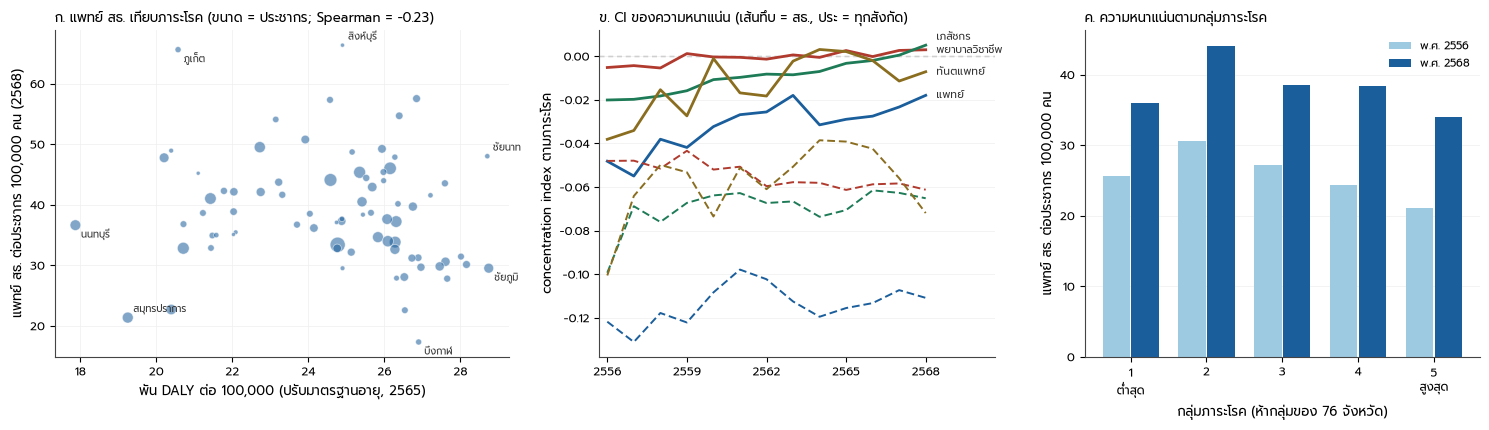

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw=dict(width_ratios=[1.15, 1, 1]))
ax = axes[0]
z = WF[(WF.cadre == "แพทย์") & (WF.scope == "moph") & (WF.year == Y1)].merge(pp[pp.year == Y1], on=["year", "prov_code"])
z["dens"] = 1e5 * z.W / z.population
z["bod"] = z.prov_code.map(BW.bod_daly)
ax.scatter(z.bod / 1000, z.dens, s=z.population / 2.2e4, color="#1b5e9c", alpha=0.55, edgecolor="white", linewidth=0.6, zorder=3)
lab_ = pd.concat([z.nlargest(2, "bod"), z.nsmallest(2, "bod"), z.nsmallest(2, "dens"), z.nlargest(2, "dens")]).drop_duplicates("prov_code")
for i, (_, r) in enumerate(lab_.sort_values("bod").iterrows()):
    ax.annotate(NAME[r.prov_code], (r.bod / 1000, r.dens), fontsize=7, xytext=(4, 4 if i % 2 else -9), textcoords="offset points", color="#333")
ax.set_xlabel("พัน DALY ต่อ 100,000 (ปรับมาตรฐานอายุ, 2565)")
ax.set_ylabel("แพทย์ สธ. ต่อประชากร 100,000 คน (2568)")
rho_ = CI[(CI.cadre == "แพทย์") & (CI.scope == "moph") & (CI.year == Y1) & (CI.rank_by == "daly")].rho_density_burden.iloc[0]
ax.set_title(f"ก. แพทย์ สธ. เทียบภาระโรค (ขนาด = ประชากร; Spearman = {rho_:+.2f})", fontsize=9.5, loc="left")
ax.grid(color="#eeeeee", linewidth=0.5, zorder=0)
ax = axes[1]
for c in CAD:
    for s, ls in [("moph", "-"), ("all_sectors", (0, (4, 2)))]:
        zz = CI[(CI.cadre == c) & (CI.scope == s) & (CI.rank_by == "daly")]
        ax.plot(zz.year, zz.ci, color=R.CADRE_COLOR[c], ls=ls, lw=2 if s == "moph" else 1.4)
ends = CI[(CI.scope == "moph") & (CI.rank_by == "daly") & (CI.year == Y1)].set_index("cadre").ci.sort_values()
ypos, last = {}, -np.inf
for c, v in ends.items():                      # keep direct labels at least 0.006 apart
    last = max(v, last + 0.006)
    ypos[c] = last
for c in CAD:
    ax.annotate(c, (Y1, ends[c]), xytext=(Y1 + 0.4, ypos[c]), textcoords="data", fontsize=7.5, color="#333", va="center")
ax.axhline(0, **R.REFLINE_KW)
R.be_ticks(ax, list(range(Y0, Y1 + 1)), step=3)
ax.set_xlim(Y0 - 0.3, Y1 + 2.6)
ax.set_ylabel("concentration index ตามภาระโรค")
ax.set_title("ข. CI ของความหนาแน่น (เส้นทึบ = สธ., ประ = ทุกสังกัด)", fontsize=9.5, loc="left")
ax.grid(axis="y", color="#eeeeee", linewidth=0.5)
ax = axes[2]
zz = QD[(QD.cadre == "แพทย์") & (QD.scope == "moph")]
xx = np.arange(5)
ax.bar(xx - 0.19, zz.density_start, width=0.36, color="#9ecae1", label=f"พ.ศ. {C.be(Y0)}")
ax.bar(xx + 0.19, zz.density_end, width=0.36, color="#1b5e9c", label=f"พ.ศ. {C.be(Y1)}")
ax.set_xticks(xx)
ax.set_xticklabels(["1\nต่ำสุด", "2", "3", "4", "5\nสูงสุด"])
ax.set_xlabel("กลุ่มภาระโรค (ห้ากลุ่มของ 76 จังหวัด)")
ax.set_ylabel("แพทย์ สธ. ต่อประชากร 100,000 คน")
ax.legend(frameon=False, fontsize=8)
ax.set_title("ค. ความหนาแน่นตามกลุ่มภาระโรค", fontsize=9.5, loc="left")
ax.grid(axis="y", color="#eeeeee", linewidth=0.5)
ax.set_axisbelow(True)
fig.tight_layout()
S.figure("F45_DENSITY_VS_BURDEN", fig, CI, "กำลังคนกับภาระโรค: แพทย์ สธ. เทียบภาระโรครายจังหวัด, concentration index 2556–2568 และความหนาแน่นตามกลุ่มภาระโรค", main=True)
plt.show()

## D4. วิชาชีพเฉพาะ: ทันตแพทย์กับภาระโรคช่องปาก
จับคู่ตามความรับผิดชอบหลักของวิชาชีพ (burden.cadre_causes) — ภาระโรคช่องปาก (S6) เป็น YLD เกือบทั้งหมด

In [17]:
cc = []
for cad, causes in BC["cadre_causes"].items():
    burden_c = bod[bod.cause_code.isin(causes)].groupby("prov_code").asr_daly.sum().drop(index=BK)
    for s in ["all_sectors", "moph"]:
        for y in [Y0, Y1]:
            z = WF[(WF.cadre == cad) & (WF.scope == s) & (WF.year == y)].merge(pp[["year", "prov_code", "population"]], on=["year", "prov_code"])
            dens = z.W / z.population
            rk = z.prov_code.map(burden_c)
            cc.append(dict(cadre=cad, causes=",".join(causes), scope=s, year=y, ci=M.concentration_index(dens, rk, z.population),
                           rho=spearmanr(dens, rk).statistic, burden_p90_p10=burden_c.quantile(.9) / burden_c.quantile(.1)))
CC = pd.DataFrame(cc)
S.table("T45_CADRE_SPECIFIC_BURDEN", CC, "ทันตแพทย์ต่อประชากรเรียงตามภาระโรคช่องปาก (S6): concentration index และสหสัมพันธ์")
display(CC.round(3))
for r in CC.itertuples():
    S.claim(f"c45_ci_{EN[r.cadre]}_oral_{r.scope}_{r.year}", r.ci, "{:+.3f}", "")
S.claim("c45_oral_p90p10", CC.burden_p90_p10.iloc[0], "{:.2f}", "เท่า")

,cadre,causes,scope,year,ci,rho,burden_p90_p10
0,ทันตแพทย์,S6,all_sectors,2013,0.000,0.171,1.679
1,ทันตแพทย์,S6,all_sectors,2025,0.029,0.277,1.679
2,ทันตแพทย์,S6,moph,2013,0.033,0.297,1.679
3,ทันตแพทย์,S6,moph,2025,0.047,0.366,1.679


1.67900939713666

## D5. จังหวัดที่ควรให้ความสำคัญเปลี่ยนไปหรือไม่ เมื่อใช้ภาระโรค (แพทย์ สธ. ปี 2568)
วิธีเดียวกับ 4.3.4: $R_p=(W_p/D_p)/(\sum W/\sum D)$, 19 จังหวัดต่ำสุด, ช่องว่างตามกฎสัดส่วน $=\sum W\,D_p/\sum D-W_p$

In [18]:
Q = BC["priority_quartile"]
PD_ = ["population", "age_scenario_moderate", "bod_pop", "bod_count", "bod_yld_count", "bod_allcause_pop"]
pri = []
for c, s in [("แพทย์", "moph"), ("แพทย์", "all_sectors"), ("พยาบาลวิชาชีพ", "moph")]:
    for d in PD_:
        z = WF[(WF.cadre == c) & (WF.scope == s) & (WF.year == Y1)].merge(DEN[(DEN.denominator == d) & (DEN.year == Y1)], on=["year", "prov_code"])
        z["R"] = (z.W / z.D) / (z.W.sum() / z.D.sum())
        z = z.sort_values(["R", "prov_code"]).reset_index(drop=True)
        z["rank"] = np.arange(1, len(z) + 1)
        z["priority"] = z["rank"] <= Q
        z["proportional_gap"] = z.W.sum() * z.D / z.D.sum() - z.W
        z["cadre"], z["scope"], z["denominator"] = c, s, d
        pri.append(z)
PRI = pd.concat(pri, ignore_index=True)
PRI["province"] = PRI.prov_code.map(NAME)
S.table("T45_PRIORITY_BURDEN", PRI[["cadre", "scope", "denominator", "year", "prov_code", "province", "W", "D", "R", "rank", "priority", "proportional_gap"]],
        "อันดับจังหวัดและช่องว่างตามกฎสัดส่วนภายใต้ตัวหารที่ถ่วงภาระโรค ปี 2568", main=True)
mp = PRI[(PRI.cadre == "แพทย์") & (PRI.scope == "moph")]
memb = mp.pivot(index="province", columns="denominator", values="priority")
rk = mp.pivot(index="province", columns="denominator", values="rank")
gap = mp.pivot(index="province", columns="denominator", values="proportional_gap")
pop_list, bod_list, boda_list = (set(memb.index[memb[d]]) for d in ["population", "bod_pop", "bod_count"])
S.text_claim("c45_pri_enter_bod", ", ".join(sorted(bod_list - pop_list, key=lambda p: rk.loc[p, "bod_pop"])) or "ไม่มี")
S.text_claim("c45_pri_exit_bod", ", ".join(sorted(pop_list - bod_list, key=lambda p: rk.loc[p, "population"])) or "ไม่มี")
S.claim("c45_pri_enter_bod_n", len(bod_list - pop_list), "int", "จังหวัด")
S.text_claim("c45_pri_enter_boda", ", ".join(sorted(boda_list - pop_list, key=lambda p: rk.loc[p, "bod_count"])) or "ไม่มี")
S.text_claim("c45_pri_exit_boda", ", ".join(sorted(pop_list - boda_list, key=lambda p: rk.loc[p, "population"])) or "ไม่มี")
S.claim("c45_pri_enter_boda_n", len(boda_list - pop_list), "int", "จังหวัด")
S.claim("c45_pri_jaccard_pop_bod", M.jaccard(pop_list, bod_list), "{:.2f}", "")
S.claim("c45_pri_jaccard_pop_bodc", M.jaccard(pop_list, boda_list), "{:.2f}", "")
S.claim("c45_pri_core_n", len(pop_list & bod_list & boda_list), "int", "จังหวัด")
S.text_claim("c45_pri_core", ", ".join(sorted(pop_list & bod_list & boda_list, key=lambda p: rk.loc[p, "bod_pop"])))
# physicians that would have to be in different provinces for proportional-to-burden allocation (2025 stock)
for d in ["population", "bod_pop", "bod_count"]:
    S.claim(f"c45_pri_gap_total_{d}", gap[d].clip(lower=0).sum(), "int", "คน", note="sum of positive proportional gaps, MOPH physicians 2025")
shift = (gap["bod_count"] - gap["population"])
S.text_claim("c45_gap_shift_up", ", ".join(f"{p} (+{shift[p]:.0f})" for p in shift.sort_values(ascending=False).index[:5]))
S.text_claim("c45_gap_shift_down", ", ".join(f"{p} ({shift[p]:.0f})" for p in shift.sort_values().index[:5]))
if PRI43 is not None:
    m43 = PRI43[(PRI43.cadre == "แพทย์") & (PRI43.scope == "moph")].pivot(index="province", columns="denominator", values="priority")
    six = ["population", "entitlement", "age_scenario_moderate", "op_visits", "ip_days", "adjrw"]
    all6 = set(m43.index[m43[six].all(axis=1)])
    S.claim("c45_pri_all6_in_bod_n", len(all6 & bod_list), "int", "จังหวัด")
    S.claim("c45_pri_all6_n", len(all6), "int", "จังหวัด")
    svc = set(m43.index[m43["op_visits"]])
    S.claim("c45_pri_bod_op_intersection", len(bod_list & svc), "int", "จังหวัด")
    S.claim("c45_pri_bodc_op_intersection", len(boda_list & svc), "int", "จังหวัด")
display(rk.loc[sorted(pop_list | bod_list | boda_list, key=lambda p: rk.loc[p, "bod_pop"]), PD_])

denominator,population,age_scenario_moderate,bod_pop,bod_count,bod_yld_count,bod_allcause_pop
province,,,,,,
บึงกาฬ,1,1,1,1,1,1
หนองบัวลำภู,3,3,2,2,2,2
สระแก้ว,5,6,3,6,13,3
ชัยภูมิ,9,8,4,3,10,4
นราธิวาส,7,11,5,20,20,7
อำนาจเจริญ,6,5,6,7,3,6
กำแพงเพชร,12,10,7,5,7,5
เพชรบูรณ์,11,9,8,4,12,9
ปัตตานี,10,17,9,26,34,11


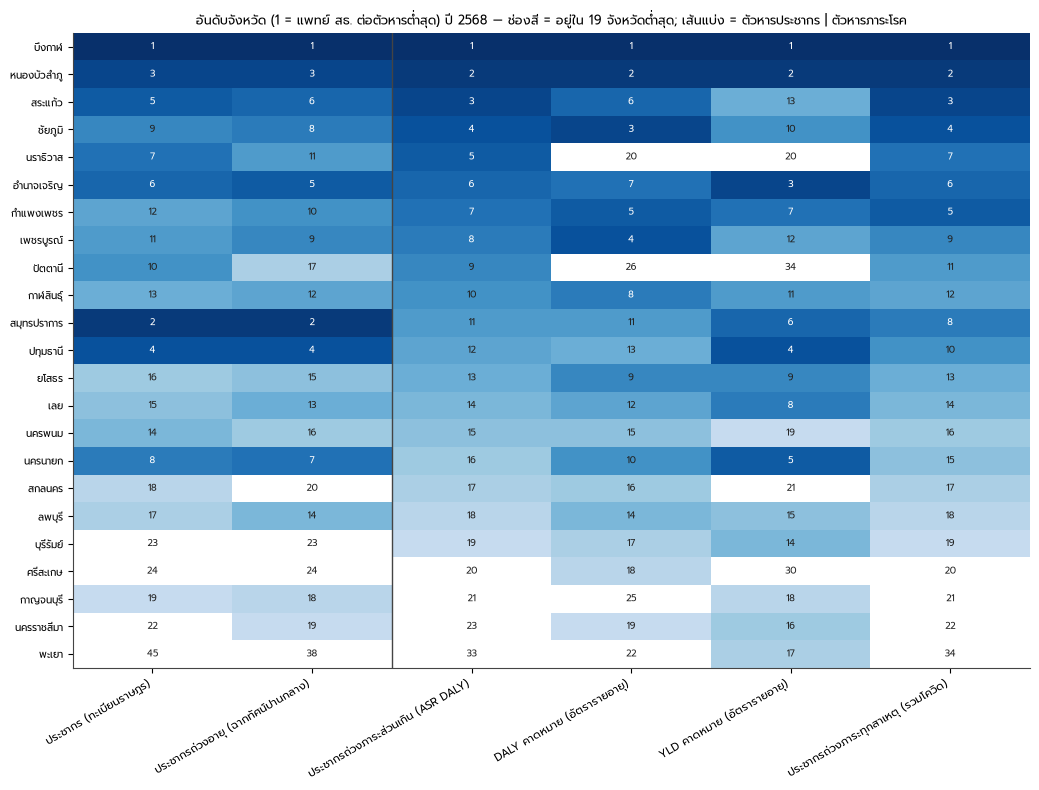

In [19]:
fig, ax = plt.subplots(figsize=(10.5, 8))
show = sorted(pop_list | bod_list | boda_list | set(memb.index[memb[PD_].any(axis=1)]), key=lambda p: rk.loc[p, "bod_pop"])
mat = rk.loc[show, PD_].to_numpy(float)
ax.imshow(np.where(mat <= Q, mat, np.nan), cmap="Blues_r", aspect="auto", vmin=1, vmax=Q + 6)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{int(mat[i, j])}", ha="center", va="center", fontsize=6.8, color="white" if mat[i, j] <= 8 else "#222")
ax.set_xticks(range(len(PD_)))
ax.set_xticklabels([DEN_TH[d] for d in PD_], rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(show)))
ax.set_yticklabels(show, fontsize=7.2)
ax.axvline(1.5, color="#444", lw=1)
ax.set_title("อันดับจังหวัด (1 = แพทย์ สธ. ต่อตัวหารต่ำสุด) ปี 2568 — ช่องสี = อยู่ใน 19 จังหวัดต่ำสุด; เส้นแบ่ง = ตัวหารประชากร | ตัวหารภาระโรค", fontsize=9)
fig.tight_layout()
S.figure("F45_PRIORITY_BURDEN", fig, mp, "จังหวัดที่ควรให้ความสำคัญเมื่อใช้ตัวหารที่ถ่วงภาระโรค เทียบตัวหารประชากร (แพทย์ สธ. ปี 2568)", main=True)
plt.show()

---
# ส่วน E — ดัชนีภาระโรคสำหรับบทที่ 5 และความพร้อมของข้อมูล
บทที่ 5 สร้างตระกูลตัวหาร **B (DALY คาดหมาย = ประชากรฉายรายกลุ่มอายุ × อัตรารายอายุปี 2565)** จาก `chapter4.panels` โดยตรง และใช้ดัชนี ASR เป็นความไว ตารางนี้ส่งออกค่าที่ใช้เพื่อการตรวจสอบ

In [20]:
RBX = RB.merge(BW[["bod_daly", "bod_yld", "bod_yll", "bod_daly_allcause", "bod_daly_crude", "bod_daly_count_2022"]].reset_index(), on="prov_code")
RBX = RBX.merge(ar.pivot(index="prov_code", columns="age_group", values="rate_daly").mul(1e5).add_prefix("daly_rate_age").reset_index(), on="prov_code")
S.table("T45_BURDEN_INDEX", RBX, "ดัชนีภาระส่วนเกิน RB (ASR) และอัตรา DALY รายอายุของแต่ละจังหวัด (ต่อ 100,000) ที่ใช้สร้างตัวหาร B ในบทที่ 5")
READY = pd.DataFrame([
    dict(input="ภาระโรคปรับมาตรฐานอายุรายจังหวัด 174 กลุ่มโรค (DALY/YLL/YLD/ตาย)", status="มี (BOD 2565)", type="ประมาณการจากแบบจำลอง",
         gap="ปีเดียว; ไม่มีจำนวนนับหรืออัตรารายอายุ จึงฉายภาระรวมตามการสูงวัยโดยตรงไม่ได้"),
    dict(input="ภาระโรครายกลุ่มอายุ (8 กลุ่ม) รายจังหวัด", status="มี (BOD 2565, รวมเพศ)", type="ประมาณการจากแบบจำลอง",
         gap="ฉายภาระตามการสูงวัยได้โดยตรึงอัตรารายอายุปี 2565; ไม่แยกเพศ"),
    dict(input="ภาระโรครายจังหวัดหลายปี", status="ไม่มี (มีเฉพาะระดับประเทศ)", type="—",
         gap="แนวโน้มของอัตรารายอายุรายจังหวัดและผลของโควิด-19 แยกไม่ได้; แนวโน้มระดับประเทศไม่เปลี่ยนส่วนแบ่งรายจังหวัด"),
    dict(input="การเชื่อมภาระโรคกับชุดบริการและเวลาต่อวิชาชีพ", status="ไม่มี", type="ต้องตัดสินเชิงบรรทัดฐาน",
         gap="ภาระโรคบอกขนาดของปัญหาสุขภาพ ไม่ได้บอกจำนวนบุคลากรที่ต้องการโดยตรง"),
])
S.table("T45_NEED_READINESS_UPDATE", READY, "ความพร้อมของข้อมูลความจำเป็นหลังเพิ่มภาระโรครายจังหวัด")
display(READY)

,input,status,type,gap
0,ภาระโรคปรับมาตรฐานอายุรายจังหวัด 174 กลุ่มโรค ...,มี (BOD 2565),ประมาณการจากแบบจำลอง,ปีเดียว; ไม่มีจำนวนนับหรืออัตรารายอายุ จึงฉายภ...
1,ภาระโรครายกลุ่มอายุ (8 กลุ่ม) รายจังหวัด,"มี (BOD 2565, รวมเพศ)",ประมาณการจากแบบจำลอง,ฉายภาระตามการสูงวัยได้โดยตรึงอัตรารายอายุปี 25...
2,ภาระโรครายจังหวัดหลายปี,ไม่มี (มีเฉพาะระดับประเทศ),—,แนวโน้มของอัตรารายอายุรายจังหวัดและผลของโควิด-...
3,การเชื่อมภาระโรคกับชุดบริการและเวลาต่อวิชาชีพ,ไม่มี,ต้องตัดสินเชิงบรรทัดฐาน,ภาระโรคบอกขนาดของปัญหาสุขภาพ ไม่ได้บอกจำนวนบุค...


In [21]:
manifest = S.finalize(extra_manifest=dict(burden_year=BY, excluded_causes=BC["exclude_causes"], folds_seed=MC["cv_seed"]))
print({k: manifest[k] for k in ["n_tables", "n_figures", "n_claims", "seconds"]})

{'n_tables': 20, 'n_figures': 6, 'n_claims': 650, 'seconds': 10.9}
